<a href="https://colab.research.google.com/github/sergeregtoumda/multimodalTwibot22/blob/main/Multimodal_MLP_XLM_RoBERTa_ViT_30_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Récupération du dataset**

# Creation d'un nouveau dataset à partir de Twibot-22

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install pandas ijson requests tqdm

In [ ]:
import os
import ijson
import pandas as pd
from tqdm import tqdm

# Chemin vers le dossier contenant les fichiers TwiBot-22
DATA_DIR = "/content/drive/MyDrive/TwiBot-22"  # À adapter (ex: "/content/drive/MyDrive/TwiBot-22")
OUTPUT_CSV = "twibot_dataset.csv"

# 1. Chargement des labels et des splits en dictionnaires pour une jointure rapide
print("Chargement de label.csv et split.csv...")
labels_df = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))
splits_df = pd.read_csv(os.path.join(DATA_DIR, "split.csv"))

label_map = dict(zip(labels_df["id"], labels_df["label"]))
split_map = dict(zip(splits_df["id"], splits_df["split"]))

# 2. Lecture en streaming de user.json
user_json_path = os.path.join(DATA_DIR, "user.json")
records = []

print("Extraction des profils depuis user.json...")
with open(user_json_path, "rb") as f:
    # ijson.items permet d'itérer objet par objet sans tout charger en RAM
    users = ijson.items(f, "item")
    for user in tqdm(users, total=1000000, desc="Traitement des utilisateurs"):
        uid = user.get("id")
        if not uid:
            continue

        metrics = user.get("public_metrics") or {}
        img_url = user.get("profile_image_url", "")

        records.append({
            "id": uid,
            "username": user.get("username", ""),
            "name": user.get("name", ""),
            "description": user.get("description", ""),
            "location": user.get("location", ""),
            "verified": int(bool(user.get("verified", False))),
            "protected": int(bool(user.get("protected", False))),
            "created_at": user.get("created_at", ""),
            "followers_count": metrics.get("followers_count", 0),
            "following_count": metrics.get("following_count", 0),
            "tweet_count": metrics.get("tweet_count", 0),
            "listed_count": metrics.get("listed_count", 0),
            "profile_image_url": img_url,
            "image_path": f"profile_images/{uid}.jpg",
            "label": label_map.get(uid, "unknown"),
            "split": split_map.get(uid, "unknown")
        })

# 3. Sauvegarde dans twibot_dataset.csv
df = pd.DataFrame(records)
df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")
print(f"Dataset sauvegardé avec succès : {OUTPUT_CSV} ({len(df)} lignes)")

Chargement de label.csv et split.csv...
Extraction des profils depuis user.json...


Traitement des utilisateurs: 100%|██████████| 1000000/1000000 [00:34<00:00, 29102.71it/s]


Dataset sauvegardé avec succès : twibot_dataset.csv (1000000 lignes)


In [4]:
import os
import requests
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

CSV_PATH = "twibot_dataset.csv"
IMAGE_DIR = "profile_images"
os.makedirs(IMAGE_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

# Optionnel : Filtrer ou échantillonner avant téléchargement
# (Télécharger 1M d'images peut être long ; vous pouvez tester sur un sous-ensemble)
# df = df.groupby("label", group_keys=False).apply(lambda x: x.sample(min(len(x), 25000), random_state=42))

def download_profile_image(row, high_res=True, timeout=5):
    uid = row["id"]
    url = str(row["profile_image_url"])
    save_path = os.path.join(IMAGE_DIR, f"{uid}.jpg")

    # Si l'image existe déjà localement, ne pas la retélécharger
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return uid, True

    if not url or not url.startswith("http"):
        return uid, False

    urls_to_try = [url.replace("_normal.", "_400x400."), url] if high_res else [url]

    for target_url in urls_to_try:
        try:
            response = requests.get(target_url, timeout=timeout, stream=True)
            if response.status_code == 200:
                with open(save_path, "wb") as f:
                    for chunk in response.iter_content(1024):
                        f.write(chunk)
                return uid, True
        except requests.RequestException:
            continue

    return uid, False

# Téléchargement parallélisé (32 threads)
print(f"Téléchargement des images dans '{IMAGE_DIR}/'...")
rows = df[["id", "profile_image_url"]].to_dict("records")
status_map = {}

with ThreadPoolExecutor(max_workers=32) as executor:
    futures = [executor.submit(download_profile_image, row) for row in rows]
    for future in tqdm(as_completed(futures), total=len(futures), desc="Téléchargement"):
        uid, success = future.result()
        status_map[uid] = success

# Ajout d'un indicateur de disponibilité de l'image et sauvegarde
df["has_valid_image"] = df["id"].map(status_map)
df.to_csv(CSV_PATH, index=False, encoding="utf-8")

valid_count = df["has_valid_image"].sum()
print(f"Terminé : {valid_count}/{len(df)} images téléchargées avec succès.")

Téléchargement des images dans 'profile_images/'...


Téléchargement: 100%|██████████| 1000000/1000000 [3:34:13<00:00, 77.80it/s]


Terminé : 495521/1000000 images téléchargées avec succès.


In [6]:
import os
import pandas as pd
import numpy as np
from PIL import Image
from tqdm import tqdm

INPUT_CSV = "twibot_dataset.csv"
IMAGE_DIR = "profile_images"
OUTPUT_CSV = "twibot_multimodal_clean.csv"

# 1. Chargement du CSV initial
df = pd.read_csv(INPUT_CSV)

# 2. Vérification stricte des images (existence + intégrité PIL)
def check_valid_image(uid):
    path = os.path.join(IMAGE_DIR, f"{uid}.jpg")
    if not os.path.exists(path) or os.path.getsize(path) < 100:
        return False
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

print("Vérification de l'intégrité des images pour ViT...")
tqdm.pandas(desc="Validation images")
df["valid_image"] = df["id"].progress_apply(check_valid_image)

# Filtrer uniquement les profils complets (avec image valide et label connu)
df_clean = df[df["valid_image"] & df["label"].isin(["human", "bot"])].copy()
print(f"Profils multimodaux valides retenus : {len(df_clean)}")
print(df_clean.groupby(["split", "label"]).size())

# 3. Ingénierie des features pour le MLP
# Encodage binaire de la cible : bot = 1, human = 0
df_clean["target"] = (df_clean["label"] == "bot").astype(int)

# Calcul de l'âge du compte (par rapport à la date de collecte TwiBot-22 : juin 2022)
ref_date = pd.to_datetime("2022-06-01", utc=True)
created_dt = pd.to_datetime(df_clean["created_at"], errors="coerce", utc=True)
df_clean["account_age_days"] = (ref_date - created_dt).dt.days.fillna(1).clip(lower=1)

# Ratios et caractéristiques comportementales pour le MLP
df_clean["followers_following_ratio"] = df_clean["followers_count"] / (df_clean["following_count"] + 1.0)
df_clean["tweets_per_day"] = df_clean["tweet_count"] / df_clean["account_age_days"]
df_clean["username_length"] = df_clean["username"].fillna("").astype(str).str.len()
df_clean["name_length"] = df_clean["name"].fillna("").astype(str).str.len()
df_clean["description_length"] = df_clean["description"].fillna("").astype(str).str.len()
df_clean["username_digit_count"] = df_clean["username"].fillna("").astype(str).apply(lambda s: sum(c.isdigit() for c in s))
df_clean["is_default_image"] = df_clean["profile_image_url"].fillna("").str.contains("default_profile").astype(int)

# 4. Construction de l'entrée textuelle structurée pour XLM-RoBERTa
df_clean["xlmr_text"] = (
    "Name: " + df_clean["name"].fillna("").astype(str) + " </s> " +
    "Username: " + df_clean["username"].fillna("").astype(str) + " </s> " +
    "Location: " + df_clean["location"].fillna("Unknown").astype(str) + " </s> " +
    "Bio: " + df_clean["description"].fillna("No bio").astype(str)
)

# 5. Échantillonnage équilibré (50% Humains / 50% Bots) par split (Train / Valid / Test)
# Vous pouvez ajuster MAX_PER_CLASS_TRAIN selon le nombre d'images que vous avez téléchargées
MAX_PER_CLASS = {"train": 20000, "valid": 3000, "test": 3000}

balanced_parts = []
for split_name, max_n in MAX_PER_CLASS.items():
    sub = df_clean[df_clean["split"] == split_name]
    bots = sub[sub["target"] == 1]
    humans = sub[sub["target"] == 0]

    n_samples = min(len(bots), len(humans), max_n)
    if n_samples > 0:
        balanced_parts.append(bots.sample(n=n_samples, random_state=42))
        balanced_parts.append(humans.sample(n=n_samples, random_state=42))

df_final = pd.concat(balanced_parts, ignore_index=True).sample(frac=1.0, random_state=42)
df_final.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")

print(f"\nDataset final généré : {OUTPUT_CSV} ({len(df_final)} lignes)")
print(pd.crosstab(df_final["split"], df_final["label"], margins=True))

Vérification de l'intégrité des images pour ViT...


Validation images: 100%|██████████| 1000000/1000000 [06:57<00:00, 2397.97it/s]


Profils multimodaux valides retenus : 495520
split  label
test   bot       20560
       human     41255
train  bot       34813
       human    285250
val    bot       34972
       human     78670
dtype: int64

Dataset final généré : twibot_multimodal_clean.csv (46000 lignes)
label    bot  human    All
split                     
test    3000   3000   6000
train  20000  20000  40000
All    23000  23000  46000


In [7]:
# Correction de la clé "val" (au lieu de "valid")
# Choix 1 : Calibre Agile 52 000 lignes (77% Train / 11.5% Val / 11.5% Test)
MAX_PER_CLASS = {"train": 20000, "val": 3000, "test": 3000}

# (Optionnel) Choix 2 : Calibre Maximal 100 000 lignes (70% Train / 15% Val / 15% Test)
# MAX_PER_CLASS = {"train": 34813, "val": 7500, "test": 7687}

balanced_parts = []
for split_name, max_n in MAX_PER_CLASS.items():
    sub = df_clean[df_clean["split"].str.strip() == split_name]
    bots = sub[sub["target"] == 1]
    humans = sub[sub["target"] == 0]

    n_samples = min(len(bots), len(humans), max_n)
    if n_samples > 0:
        balanced_parts.append(bots.sample(n=n_samples, random_state=42))
        balanced_parts.append(humans.sample(n=n_samples, random_state=42))

df_final = pd.concat(balanced_parts, ignore_index=True).sample(frac=1.0, random_state=42)
df_final.to_csv("twibot_multimodal_clean.csv", index=False, encoding="utf-8")

print(f"Dataset final corrigé : {len(df_final)} lignes")
print(pd.crosstab(df_final["split"], df_final["label"], margins=True))

Dataset final corrigé : 52000 lignes
label    bot  human    All
split                     
test    3000   3000   6000
train  20000  20000  40000
val     3000   3000   6000
All    26000  26000  52000


In [8]:
import os
import shutil
from tqdm import tqdm

SUBSET_IMG_DIR = "profile_images_subset"
os.makedirs(SUBSET_IMG_DIR, exist_ok=True)

for uid in tqdm(df_final["id"], desc="Copie des images du sous-ensemble"):
    src = os.path.join("profile_images", f"{uid}.jpg")
    dst = os.path.join(SUBSET_IMG_DIR, f"{uid}.jpg")
    if os.path.exists(src):
        shutil.copy2(src, dst)

# Compression uniquement du sous-ensemble utile
shutil.make_archive("profile_images_subset", "zip", SUBSET_IMG_DIR)
print("Archive légère créée : profile_images_subset.zip")

Copie des images du sous-ensemble: 100%|██████████| 52000/52000 [01:48<00:00, 478.92it/s]


Archive légère créée : profile_images_subset.zip


In [10]:
import os
import shutil
import tarfile
import pandas as pd
from tqdm import tqdm
from google.colab import drive

# 1. Montage de Google Drive et création du dossier de sauvegarde
drive.mount('/content/drive')
BACKUP_DIR = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup"
os.makedirs(BACKUP_DIR, exist_ok=True)

# 2. Sauvegarde du CSV final (52 000 lignes)
CSV_FILE = "twibot_multimodal_clean.csv"
df_final = pd.read_csv(CSV_FILE)

# Mise à jour de la colonne image_path pour pointer vers le dossier local standard
df_final["image_path"] = "profile_images/" + df_final["id"].astype(str) + ".jpg"
df_final.to_csv(CSV_FILE, index=False, encoding="utf-8")

shutil.copy2(CSV_FILE, os.path.join(BACKUP_DIR, CSV_FILE))
print(f"1/3 - CSV sauvegardé sur Drive : {BACKUP_DIR}/{CSV_FILE} ({len(df_final)} lignes)")

# 3. Sauvegarde de la réserve complète des 495 520 profils (si df_clean est encore en RAM)
if "df_clean" in globals():
    pool_path = os.path.join(BACKUP_DIR, "twibot_495k_valid_pool.parquet")
    df_clean.to_parquet(pool_path, index=False)
    print(f"2/3 - Réserve complète (495k profils) sauvegardée : {pool_path}")

# 4. Création d'une archive .tar contenant UNIQUEMENT les 52 000 images retenues
TAR_PATH = os.path.join(BACKUP_DIR, "profile_images_52k.tar")
print("3/3 - Création de l'archive des 52 000 images vers Google Drive...")

with tarfile.open(TAR_PATH, "w") as tar:
    for uid in tqdm(df_final["id"], desc="Archivage des images"):
        img_src = os.path.join("profile_images", f"{uid}.jpg")
        if os.path.exists(img_src):
            # On garde la structure "profile_images/u12345.jpg" dans l'archive
            tar.add(img_src, arcname=f"profile_images/{uid}.jpg")

size_mb = os.path.getsize(TAR_PATH) / (1024 ** 2)
print(f"\nSauvegarde terminée avec succès ! Taille de l'archive : {size_mb:.1f} Mo")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1/3 - CSV sauvegardé sur Drive : /content/drive/MyDrive/TwiBot22_Multimodal_Backup/twibot_multimodal_clean.csv (52000 lignes)
2/3 - Réserve complète (495k profils) sauvegardée : /content/drive/MyDrive/TwiBot22_Multimodal_Backup/twibot_495k_valid_pool.parquet
3/3 - Création de l'archive des 52 000 images vers Google Drive...


Archivage des images: 100%|██████████| 52000/52000 [02:17<00:00, 377.81it/s]



Sauvegarde terminée avec succès ! Taille de l'archive : 1473.9 Mo


In [5]:
!zip -r -q profile_images.zip profile_images/
from google.colab import files
files.download("profile_images.zip")



zip error: Interrupted (aborting)


FileNotFoundError: Cannot find file: profile_images.zip

# Recupération du datset depuis Google Drive

In [1]:
# === Restauration rapide du Dataset depuis Google Drive (Session locale) ===
import os
import shutil
import tarfile
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
BACKUP_DIR = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup"

# 1. Copie du CSV vers le disque rapide local de Colab
shutil.copy2(os.path.join(BACKUP_DIR, "twibot_multimodal_clean.csv"), "/content/twibot_multimodal_clean.csv")

# 2. Extraction ultra-rapide des 52 000 images sur le disque local (/content/profile_images/)
if not os.path.exists("/content/profile_images"):
    print("Extraction des 52 000 images sur le SSD local...")
    with tarfile.open(os.path.join(BACKUP_DIR, "profile_images_52k.tar"), "r") as tar:
        tar.extractall(path="/content/")
    print(f"Images prêtes : {len(os.listdir('/content/profile_images'))} fichiers extraits.")
else:
    print("Le dossier /content/profile_images est déjà présent.")

# 3. Vérification rapide
df = pd.read_csv("/content/twibot_multimodal_clean.csv")
print(f"Dataset chargé : {len(df)} profils prêts pour MLP + XLM-RoBERTa + ViT.")
print(pd.crosstab(df["split"], df["label"], margins=True))

Mounted at /content/drive
Extraction des 52 000 images sur le SSD local...


/tmp/ipykernel_3242/143100049.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path="/content/")


Images prêtes : 52000 fichiers extraits.
Dataset chargé : 52000 profils prêts pour MLP + XLM-RoBERTa + ViT.
label    bot  human    All
split                     
test    3000   3000   6000
train  20000  20000  40000
val     3000   3000   6000
All    26000  26000  52000


In [2]:
with open('/content/gemini-code-1793241860375.txt', 'r', encoding='utf-8') as f:
    instructions = f.read()

print(instructions)

Agis comme un expert en Deep Learning et PyTorch. Nous allons réaliser un projet de détection de faux profils (bots) sur Twitter à l'aide d'une architecture multimodale combinant trois branches : un MLP (données tabulaires), XLM-RoBERTa (texte) et un Vision Transformer - ViT (image de profil).

### RÈGLE D'EXÉCUTION STRICTE (TRÈS IMPORTANT) :
Nous travaillons dans Google Colab. Tu dois procéder **UNE SEULE ÉTAPE À LA FOIS** parmi les 7 étapes du plan ci-dessous.
- Pour chaque étape, génère une courte explication méthodologique suivie de cellules de code Python modulaires, commentées et dotées d'un titre clair (`# === Titre de la cellule ===`).
- **ARRÊTE-TOI OBLIGATOIREMENT à la fin de l'Étape 1.** Ne génère AUCUN code pour les étapes suivantes tant que je n'ai pas exécuté le code et écrit "Passe à l'étape X".

### PARAMÈTRES DU DATASET :
- Répertoire de travail : `/content/twitter_bot_project`
- Chemin du CSV : `/content/twitter_bot_project/twitter_human_bots_dataset.csv`
- Dossier de

# Étape 1 : Environnement matériel, logiciel et Reproductibilité

In [3]:
# === Étape 1 : Environnement matériel, logiciel et Reproductibilité ===

# 0. Installation silencieuse des dépendances (toujours avant les imports)
%pip install -q transformers accelerate sentencepiece datasets shap scikit-learn

import os
import sys
import random
import subprocess
import psutil
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import PIL
import torch
import transformers
import sklearn
import shap

# 1. Diagnostic de l'infrastructure matérielle (GPU, CPU, RAM)
print("=== DIAGNOSTIC MATÉRIEL ===")
try:
    gpu_info = subprocess.check_output("nvidia-smi", shell=True).decode("utf-8")
    print(gpu_info)
except Exception:
    print("Aucun GPU NVIDIA détecté ou nvidia-smi indisponible. Utilisation du processeur (CPU).")

print(f"Processeur (cœurs physiques) : {psutil.cpu_count(logical=False)}")
print(f"Processeur (cœurs logiques)  : {psutil.cpu_count(logical=True)}")
print(f"RAM totale disponible        : {psutil.virtual_memory().total / (1024**3):.2f} Go")
if torch.cuda.is_available():
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"VRAM GPU disponible          : {vram_gb:.2f} Go")

# 2. Création automatique du dossier d'export des sorties
output_dir = "/content/twibot_project/outputs"
os.makedirs(output_dir, exist_ok=True)
print(f"\nDossier de sorties configuré : {output_dir}")

# 3. Paramétrage rigoureux de la graine pour la reproductibilité académique
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)  # Assure aussi la reproductibilité côté Hugging Face
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print(f"Graine aléatoire globalement fixée à {SEED} (PyTorch, CUDA, Transformers, NumPy, Random).")

# 4. Vérification des versions logicielles
print("\n=== VÉRIFICATION DES VERSIONS ===")
print(f"Version Python         : {sys.version.split()[0]}")
print(f"Version PyTorch        : {torch.__version__}")
print(f"Version Transformers   : {transformers.__version__}")
print(f"Version Scikit-Learn   : {sklearn.__version__}")
print(f"Version Pandas         : {pd.__version__}")
print(f"Version NumPy          : {np.__version__}")
print(f"Version SHAP           : {shap.__version__}")
print(f"Version Matplotlib     : {matplotlib.__version__}")
print(f"Version Seaborn        : {sns.__version__}")
print(f"Version Pillow (PIL)   : {PIL.__version__}")

# 5. Définition globale du périphérique de calcul (Device)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nPériphérique actif pour PyTorch : {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

=== DIAGNOSTIC MATÉRIEL ===
Fri Oct 30 16:07:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-------------------

# Étape 2 : Chargement des données, Prétraitement et Préparation des Splits

In [4]:
# === Étape 2 : Cellule 1/2 - Chargement, Nettoyage et Gestion des Chemins d'Images (TwiBot-22) ===

import os
import pandas as pd
import numpy as np
from PIL import Image
from tqdm import tqdm

# Chemins issus de la restauration TwiBot-22
csv_path = "/content/twibot_multimodal_clean.csv"
images_dir = "/content/profile_images"

# 1. Chargement et suppression des doublons sur l'identifiant unique
df_raw = pd.read_csv(csv_path)
df_raw = df_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)
print(f"Dimensions initiales du dataset après dédoublonnage : {df_raw.shape}")

# 2. Encodage de la cible (label : human -> 0, bot -> 1)
# Compatible avec 'label' (TwiBot-22) ou 'account_type' (ancien dataset)
target_col = "label" if "label" in df_raw.columns else "account_type"
if df_raw[target_col].dtype == "object":
    df_raw["target"] = (df_raw[target_col].str.lower().str.strip() == "bot").astype(int)
else:
    df_raw["target"] = df_raw[target_col].astype(int)

# 3. Gestion des champs textuels (remplacement des NaN par des chaînes vides)
for col in ["name", "username", "location", "description"]:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].fillna("").astype(str)

# Si la colonne combinée 'xlmr_text' n'existe pas encore, on la crée pour XLM-RoBERTa
if "xlmr_text" not in df_raw.columns:
    df_raw["xlmr_text"] = (
        "Name: " + df_raw["name"] + " </s> " +
        "Username: " + df_raw["username"] + " </s> " +
        "Location: " + df_raw["location"].replace("", "Unknown") + " </s> " +
        "Bio: " + df_raw["description"].replace("", "No bio")
    )

# 4. Reconstruction des chemins d'images absolus basés sur l'ID TwiBot-22 ({id}.jpg)
df_raw["absolute_image_path"] = df_raw["id"].astype(str).apply(
    lambda uid: os.path.join(images_dir, f"{uid}.jpg")
)

# Vérification physique rapide des images
missing_or_corrupt_count = 0
valid_image_paths = []

for img_path in tqdm(df_raw["absolute_image_path"], desc="Vérification des images locales"):
    if img_path and os.path.exists(img_path) and os.path.getsize(img_path) >= 100:
        valid_image_paths.append(img_path)
    else:
        valid_image_paths.append(None)
        missing_or_corrupt_count += 1

df_raw["absolute_image_path"] = valid_image_paths
print(f"\nNombre de profils avec image absente/corrompue : {missing_or_corrupt_count}")

# Affichage de la distribution de la variable cible
target_summary = df_raw["target"].value_counts().to_frame("Nombre")
target_summary["Pourcentage (%)"] = (df_raw["target"].value_counts(normalize=True) * 100).round(2)
display(target_summary)

# === Complément statistique (Texte manquant & Tableau complet pour le mémoire) ===

# 1. Comptage des descriptions (biographies) vides
empty_text_count = (df_raw["description"].str.strip() == "").sum()
print(f"Nombre de profils avec biographie (description) vide : {empty_text_count} ({empty_text_count/len(df_raw)*100:.1f}%)")
print(f"Nombre de profils avec image absente/corrompue       : {missing_or_corrupt_count} ({missing_or_corrupt_count/len(df_raw)*100:.1f}%)")

# 2. Tableau récapitulatif global formaté avec la ligne Total
summary_table = pd.DataFrame({
    "Catégorie de profil": ["Profils authentiques (0 - Human)", "Faux profils (1 - Bot)", "Total des comptes"],
    "Nombre de comptes": [
        (df_raw["target"] == 0).sum(),
        (df_raw["target"] == 1).sum(),
        len(df_raw)
    ],
    "Pourcentage (%)": [
        round((df_raw["target"] == 0).mean() * 100, 2),
        round((df_raw["target"] == 1).mean() * 100, 2),
        100.0
    ]
})
display(summary_table)

# 3. Tableau récapitulatif par partition officielle TwiBot-22 (Train / Val / Test)
if "split" in df_raw.columns:
    print("\n=== Répartition par partition officielle (TwiBot-22) ===")
    split_table = pd.crosstab(df_raw["split"], df_raw["label"], margins=True, margins_name="Total")
    display(split_table)

Dimensions initiales du dataset après dédoublonnage : (52000, 28)


Vérification des images locales: 100%|██████████| 52000/52000 [00:00<00:00, 189797.59it/s]


Nombre de profils avec image absente/corrompue : 0


,Nombre,Pourcentage (%)
target,,
0,26000,50.0
1,26000,50.0


Nombre de profils avec biographie (description) vide : 15053 (28.9%)
Nombre de profils avec image absente/corrompue       : 0 (0.0%)


,Catégorie de profil,Nombre de comptes,Pourcentage (%)
0,Profils authentiques (0 - Human),26000,50.0
1,Faux profils (1 - Bot),26000,50.0
2,Total des comptes,52000,100.0



=== Répartition par partition officielle (TwiBot-22) ===


label,bot,human,Total
split,,,
test,3000,3000,6000
train,20000,20000,40000
val,3000,3000,6000
Total,26000,26000,52000


In [5]:
# === Étape 2 : Cellule 2/2 - Ingénierie Tabulaire, Splits Officiels et Standardisation Stricte (TwiBot-22) ===

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Garantie de présence de toutes les variables dérivées TwiBot-22 dans df_raw
ref_date = pd.to_datetime("2022-06-01", utc=True)
if "account_age_days" not in df_raw.columns:
    created_dt = pd.to_datetime(df_raw["created_at"], errors="coerce", utc=True)
    df_raw["account_age_days"] = (ref_date - created_dt).dt.days.fillna(1).clip(lower=1)

if "tweets_per_day" not in df_raw.columns:
    df_raw["tweets_per_day"] = df_raw["tweet_count"] / df_raw["account_age_days"]

if "followers_following_ratio" not in df_raw.columns:
    df_raw["followers_following_ratio"] = df_raw["followers_count"] / (df_raw["following_count"] + 1.0)

if "is_default_image" not in df_raw.columns:
    df_raw["is_default_image"] = df_raw["profile_image_url"].fillna("").str.contains("default_profile").astype(int)

if "has_location" not in df_raw.columns:
    df_raw["has_location"] = (df_raw["location"].fillna("").str.strip() != "").astype(int)

# 2. Liste des 10 features tabulaires adaptées au schéma TwiBot-22 (6 numériques + 4 booléennes)
numeric_cols = [
    "followers_count",
    "following_count",      # remplace friends_count (API v2)
    "listed_count",         # remplace favourites_count (API v2)
    "tweet_count",          # remplace statuses_count (API v2)
    "tweets_per_day",       # remplace average_tweets_per_day
    "account_age_days"
]

bool_cols = [
    "protected",            # remplace default_profile (API v2)
    "is_default_image",     # remplace default_profile_image
    "has_location",         # remplace geo_enabled (API v2)
    "verified"
]

# Conversion stricte des variables booléennes en entiers 0/1
for col in bool_cols:
    df_raw[col] = df_raw[col].astype(float).fillna(0.0).astype(int)

all_tabular_cols = numeric_cols + bool_cols

# 3. Imputation des valeurs manquantes éventuelles et écrêtage des valeurs négatives
for col in all_tabular_cols:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
    if df_raw[col].isnull().any():
        df_raw[col] = df_raw[col].fillna(df_raw[col].median())

# Transformation log1p sur les variables de comptage asymétriques (stabilise le MLP)
df_tabular_prep = df_raw.copy()
for col in numeric_cols:
    df_tabular_prep[col] = np.log1p(df_tabular_prep[col].clip(lower=0))

# 4. Découpage selon les partitions officielles de TwiBot-22 (ou fallback stratifié)
if "split" in df_raw.columns and set(["train", "val", "test"]).issubset(set(df_raw["split"].str.strip().unique())):
    print("Utilisation des partitions officielles TwiBot-22 (train / val / test)...")
    split_series = df_raw["split"].str.strip()
    train_df = df_raw[split_series == "train"].copy()
    val_df   = df_raw[split_series == "val"].copy()
    test_df  = df_raw[split_series == "test"].copy()
else:
    print("Colonne 'split' incomplète : découpage stratifié 70% Train / 15% Val / 15% Test...")
    train_df, temp_df = train_test_split(
        df_raw, test_size=0.30, stratify=df_raw["target"], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df["target"], random_state=SEED
    )

print(f"\nDistribution après découpage :")
print(f"- Entraînement : {train_df.shape[0]} comptes (Bots : {(train_df['target']==1).sum()} | Humains : {(train_df['target']==0).sum()})")
print(f"- Validation   : {val_df.shape[0]} comptes (Bots : {(val_df['target']==1).sum()} | Humains : {(val_df['target']==0).sum()})")
print(f"- Test         : {test_df.shape[0]} comptes (Bots : {(test_df['target']==1).sum()} | Humains : {(test_df['target']==0).sum()})")

# 5. Standardisation stricte : Ajustement du scaler UNIQUEMENT sur l'ensemble d'entraînement
scaler = StandardScaler()
train_numeric_scaled = scaler.fit_transform(df_tabular_prep.loc[train_df.index, all_tabular_cols])
val_numeric_scaled   = scaler.transform(df_tabular_prep.loc[val_df.index, all_tabular_cols])
test_numeric_scaled  = scaler.transform(df_tabular_prep.loc[test_df.index, all_tabular_cols])

# Re-conversion en DataFrames pandas en conservant les index exacts de train_df, val_df et test_df
train_numeric_scaled_df = pd.DataFrame(train_numeric_scaled, columns=all_tabular_cols, index=train_df.index)
val_numeric_scaled_df   = pd.DataFrame(val_numeric_scaled, columns=all_tabular_cols, index=val_df.index)
test_numeric_scaled_df  = pd.DataFrame(test_numeric_scaled, columns=all_tabular_cols, index=test_df.index)

print(f"\nPrétraitement et mise à l'échelle terminés avec succès ({len(all_tabular_cols)} features tabulaires).")
display(train_numeric_scaled_df.head(3))

Utilisation des partitions officielles TwiBot-22 (train / val / test)...

Distribution après découpage :
- Entraînement : 40000 comptes (Bots : 20000 | Humains : 20000)
- Validation   : 6000 comptes (Bots : 3000 | Humains : 3000)
- Test         : 6000 comptes (Bots : 3000 | Humains : 3000)

Prétraitement et mise à l'échelle terminés avec succès (10 features tabulaires).


,followers_count,following_count,listed_count,tweet_count,tweets_per_day,account_age_days,protected,is_default_image,has_location,verified
0,0.700259,0.815983,0.603857,1.227283,1.771424,0.111563,-0.248306,-0.386769,-1.175984,-0.249608
1,0.335707,0.249507,0.121686,0.805354,0.355424,0.483903,-0.248306,-0.386769,0.850352,-0.249608
2,-0.082144,0.034610,-0.246886,0.156716,-0.064321,-0.903840,-0.248306,-0.386769,-1.175984,-0.249608


# Étape 3 : Dataset Multimodal PyTorch et DataLoaders

In [6]:
# === Étape 3 : Dataset Multimodal PyTorch et DataLoaders (TwiBot-22) ===

import os
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoImageProcessor
from PIL import Image
import numpy as np

# Désactivation du parallélisme interne du tokenizer pour éviter tout avertissement avec DataLoader
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# 1. Chargement et initialisation des processeurs Hugging Face
print("Chargement du tokenizer XLM-RoBERTa et du processeur ViT...")
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
image_processor = AutoImageProcessor.from_pretrained("google/vit-base-patch16-224", use_fast=True)

# 2. Classe Dataset Multimodale adaptée à TwiBot-22
class MultimodalDataset(Dataset):
    def __init__(self, df, numeric_scaled_df, tokenizer, image_processor, max_length=128):
        # Réinitialisation stricte des index pour aligner le DataFrame et les features standardisées
        df_reset = df.reset_index(drop=True)
        self.numeric_features = numeric_scaled_df.reset_index(drop=True).values.astype(np.float32)
        self.tokenizer = tokenizer
        self.image_processor = image_processor
        self.max_length = max_length

        # Utilisation du texte structuré complet (xlmr_text) si présent, sinon description
        text_col = "xlmr_text" if "xlmr_text" in df_reset.columns else "description"
        self.texts = df_reset[text_col].fillna("").astype(str).tolist()

        # Stockage en listes/tableaux natifs (plus rapide que .loc[] dans __getitem__ et compatible multiprocessing)
        self.image_paths = df_reset["absolute_image_path"].tolist()
        self.labels = df_reset["target"].values.astype(np.int64)

        # Pré-tokenisation globale des textes en mémoire pour accélérer les époques
        self.tokenized_texts = self.tokenizer(
            self.texts,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # a) Caractéristiques tabulaires standardisées (10 features TwiBot-22)
        num_feats = torch.from_numpy(self.numeric_features[idx])

        # b) Données textuelles pré-tokenisées (XLM-RoBERTa)
        input_ids = self.tokenized_texts["input_ids"][idx]
        attention_mask = self.tokenized_texts["attention_mask"][idx]

        # c) Image de profil (ViT) avec image noire de secours si absente ou illisible
        img_path = self.image_paths[idx]
        if img_path is not None and isinstance(img_path, str):
            try:
                with Image.open(img_path) as raw_img:
                    img = raw_img.convert("RGB")
            except Exception:
                img = Image.fromarray(np.zeros((224, 224, 3), dtype=np.uint8))
        else:
            img = Image.fromarray(np.zeros((224, 224, 3), dtype=np.uint8))

        # Prétraitement ViT (normalisation et redimensionnement 224x224)
        pixel_values = self.image_processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0)

        # d) Variable cible (0 = Human, 1 = Bot)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return {
            "numeric_features": num_feats,
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "pixel_values": pixel_values,
            "label": label
        }

# 3. Instanciation des Datasets TwiBot-22
print("Pré-tokenisation des partitions Train, Val et Test en cours...")
train_dataset = MultimodalDataset(train_df, train_numeric_scaled_df, tokenizer, image_processor)
val_dataset   = MultimodalDataset(val_df, val_numeric_scaled_df, tokenizer, image_processor)
test_dataset  = MultimodalDataset(test_df, test_numeric_scaled_df, tokenizer, image_processor)

# 4. Configuration des DataLoaders avec reproductibilité et accélération matérielle
BATCH_SIZE = 16
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
PIN_MEMORY = torch.cuda.is_available()

g = torch.Generator()
g.manual_seed(SEED if "SEED" in globals() else 42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=g
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print(f"\nDataLoaders TwiBot-22 créés avec succès (Batch = {BATCH_SIZE}, Workers = {NUM_WORKERS}).")
print(f"- Batches d'entraînement : {len(train_loader)} ({len(train_dataset)} profils)")
print(f"- Batches de validation  : {len(val_loader)} ({len(val_dataset)} profils)")
print(f"- Batches de test        : {len(test_loader)} ({len(test_dataset)} profils)\n")

# 5. Test rapide d'extraction et vérification des dimensions d'un premier batch
sample_batch = next(iter(train_loader))
for key, tensor in sample_batch.items():
    print(f"{key:<18} -> shape: {str(list(tensor.shape)):<20} | dtype: {tensor.dtype}")

Chargement du tokenizer XLM-RoBERTa et du processeur ViT...


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Pré-tokenisation des partitions Train, Val et Test en cours...

DataLoaders TwiBot-22 créés avec succès (Batch = 16, Workers = 2).
- Batches d'entraînement : 2500 (40000 profils)
- Batches de validation  : 375 (6000 profils)
- Batches de test        : 375 (6000 profils)

numeric_features   -> shape: [16, 10]             | dtype: torch.float32
input_ids          -> shape: [16, 128]            | dtype: torch.int64
attention_mask     -> shape: [16, 128]            | dtype: torch.int64
pixel_values       -> shape: [16, 3, 224, 224]    | dtype: torch.float32
label              -> shape: [16]                 | dtype: torch.int64


# Étape 4 : Architecture modulable (MultimodalClassifier et Ablation)

In [7]:
# === Étape 4 : Architecture Modulable (MultimodalClassifier - TwiBot-22) ===

import torch
import torch.nn as nn
from transformers import XLMRobertaModel, ViTModel

# Détection dynamique du nombre de variables tabulaires issues de l'Étape 2 (10 par défaut)
DEFAULT_NUM_FEATURES = len(all_tabular_cols) if "all_tabular_cols" in globals() else 10

class MultimodalClassifier(nn.Module):
    def __init__(self, mode="all", num_numeric_features=DEFAULT_NUM_FEATURES, freeze_backbone=True):
        super(MultimodalClassifier, self).__init__()
        self.mode = mode.lower()
        self.freeze_backbone = freeze_backbone

        self.use_mlp = ("mlp" in self.mode) or (self.mode == "all")
        self.use_xlm = ("xlm" in self.mode) or (self.mode == "all")
        self.use_vit = ("vit" in self.mode) or (self.mode == "all")

        if not (self.use_mlp or self.use_xlm or self.use_vit):
            raise ValueError(f"Mode '{mode}' invalide. Utilisez 'all' ou une combinaison de 'mlp', 'xlm', 'vit'.")

        # 1. Branche Numérique (MLP) : Entrée (10) -> Cachée (128) -> Sortie latente normalisée (64)
        if self.use_mlp:
            self.mlp = nn.Sequential(
                nn.Linear(num_numeric_features, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, 64),
                nn.LayerNorm(64),
                nn.ReLU()
            )

        # 2. Branche Textuelle (XLM-RoBERTa) : Sortie latente (768)
        if self.use_xlm:
            self.xlm_extractor = XLMRobertaModel.from_pretrained("xlm-roberta-base", add_pooling_layer=False)
            self.xlm_norm = nn.LayerNorm(768)
            if self.freeze_backbone:
                for param in self.xlm_extractor.parameters():
                    param.requires_grad = False

        # 3. Branche Visuelle (ViT) : Sortie latente (768)
        if self.use_vit:
            self.vit_extractor = ViTModel.from_pretrained("google/vit-base-patch16-224", add_pooling_layer=False)
            self.vit_norm = nn.LayerNorm(768)
            if self.freeze_backbone:
                for param in self.vit_extractor.parameters():
                    param.requires_grad = False

        # Détermination de la dimension d'entrée de la tête de classification après fusion
        self.fusion_dim = 0
        if self.use_mlp:
            self.fusion_dim += 64
        if self.use_xlm:
            self.fusion_dim += 768
        if self.use_vit:
            self.fusion_dim += 768

        # 4. Bloc de Fusion et Classification Finale (64 + 768 + 768 = 1600 -> 128 -> 2)
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion_dim, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)  # Sortie à 2 classes (0 = human, 1 = bot)
        )

    def forward(self, numeric_features, input_ids, attention_mask, pixel_values):
        features_to_concat = []

        # a) Passage dans la branche numérique (MLP)
        if self.use_mlp:
            p_out = self.mlp(numeric_features)
            features_to_concat.append(p_out)

        # b) Passage dans la branche textuelle (XLM-RoBERTa)
        if self.use_xlm:
            if self.freeze_backbone:
                self.xlm_extractor.eval()
            with torch.set_grad_enabled(not self.freeze_backbone):
                xlm_outputs = self.xlm_extractor(input_ids=input_ids, attention_mask=attention_mask)
                # Récupération de la représentation du premier token <s> (CLS token)
                t_out = xlm_outputs.last_hidden_state[:, 0, :]
            t_out = self.xlm_norm(t_out)
            features_to_concat.append(t_out)

        # c) Passage dans la branche visuelle (ViT)
        if self.use_vit:
            if self.freeze_backbone:
                self.vit_extractor.eval()
            with torch.set_grad_enabled(not self.freeze_backbone):
                vit_outputs = self.vit_extractor(pixel_values=pixel_values)
                # Récupération du token CLS
                v_out = vit_outputs.last_hidden_state[:, 0, :]
            v_out = self.vit_norm(v_out)
            features_to_concat.append(v_out)

        # d) Concaténation des modalités actives et classification finale
        z = torch.cat(features_to_concat, dim=-1)
        logits = self.classifier(z)
        return logits

print("Classe MultimodalClassifier définie et paramétrée avec succès.")

# === Vérification rapide de l'architecture et du nombre de paramètres ===
test_model = MultimodalClassifier(mode="all", freeze_backbone=True).to(device)
total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print(f"- Dimension du vecteur de fusion (mode='all') : {test_model.fusion_dim}")
print(f"- Paramètres totaux                           : {total_params:,}")
print(f"- Paramètres entraînables (freeze=True)       : {trainable_params:,}")

# Test d'un passage forward sur le sample_batch de l'Étape 3
if "sample_batch" in globals():
    test_model.eval()
    with torch.no_grad():
        sample_logits = test_model(
            sample_batch["numeric_features"].to(device),
            sample_batch["input_ids"].to(device),
            sample_batch["attention_mask"].to(device),
            sample_batch["pixel_values"].to(device)
        )
    print(f"- Test forward réussi ! Forme des logits de sortie : {list(sample_logits.shape)}")
del test_model
torch.cuda.empty_cache()

Classe MultimodalClassifier définie et paramétrée avec succès.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


- Dimension du vecteur de fusion (mode='all') : 1600
- Paramètres totaux                           : 363,470,274
- Paramètres entraînables (freeze=True)       : 218,562
- Test forward réussi ! Forme des logits de sortie : [16, 2]


In [8]:
# === Étape 4 (Suite) : Validation par passage avant (Forward Pass) ===

# 1. Extraction des tenseurs du batch d'exemple généré à l'étape 3
num_feats = sample_batch['numeric_features'].to(device)
input_ids = sample_batch['input_ids'].to(device)
attention_mask = sample_batch['attention_mask'].to(device)
pixel_values = sample_batch['pixel_values'].to(device)

# 2. Instanciation du modèle complet en mode "all" pour test
print("Instanciation et test du modèle multimodal complet (mode='all')...")
test_forward_model = MultimodalClassifier(mode="all", freeze_backbone=True).to(device)
test_forward_model.eval()

with torch.no_grad():
    output_logits = test_forward_model(num_feats, input_ids, attention_mask, pixel_values)

print(f"\n=== RÉSULTATS DU PASSAGE AVANT DE TEST ===")
print(f"Dimension de la sortie (logits) : {list(output_logits.shape)}")
print(f"Logits d'exemple (premiers comptes) :\n{output_logits[:3]}")

# 3. Vérification formelle de la forme des tenseurs de sortie
assert list(output_logits.shape) == [16, 2], f"Erreur de dimension : attendu [16, 2], obtenu {list(output_logits.shape)}"
print("\nValidation réussie ! L'architecture est parfaitement compatible avec les DataLoaders TwiBot-22.")

# Nettoyage de la mémoire GPU
del test_forward_model
torch.cuda.empty_cache()

Instanciation et test du modèle multimodal complet (mode='all')...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== RÉSULTATS DU PASSAGE AVANT DE TEST ===
Dimension de la sortie (logits) : [16, 2]
Logits d'exemple (premiers comptes) :
tensor([[ 0.2299, -0.4824],
        [-0.0556, -0.2591],
        [ 0.4662, -0.3594]], device='cuda:0')

Validation réussie ! L'architecture est parfaitement compatible avec les DataLoaders TwiBot-22.


# Étape 5 : Entraînement, Validation et Courbes d'apprentissage

In [9]:
# # === Étape 5 : Cellule 1/2 - Fonctions d'Entraînement et de Visualisation (TwiBot-22) ===

# import os
# import shutil
# import time
# import torch
# import torch.nn as nn
# import torch.optim as optim
# from sklearn.metrics import f1_score, accuracy_score
# import matplotlib.pyplot as plt
# from tqdm.auto import tqdm

# # Dossiers de sortie (local + sauvegarde automatique Google Drive si monté)
# output_dir = "/content/twitter_bot_project/outputs"
# os.makedirs(output_dir, exist_ok=True)

# drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"
# if os.path.exists("/content/drive/MyDrive"):
#     os.makedirs(drive_backup_dir, exist_ok=True)

# def train_model(mode="all", epochs=5, lr=1e-3, patience=2):
#     print(f"\n=== Début de l'entraînement TwiBot-22 en mode : {mode.upper()} ===")
#     start_time = time.time()

#     # 1. Instanciation du modèle et transfert sur le périphérique cible (CPU/GPU)
#     model = MultimodalClassifier(mode=mode, freeze_backbone=True).to(device)

#     # 2. Critère de perte et optimiseur (uniquement sur les paramètres entraînables)
#     criterion = nn.CrossEntropyLoss()
#     trainable_params = [p for p in model.parameters() if p.requires_grad]
#     optimizer = optim.AdamW(trainable_params, lr=lr, weight_decay=1e-4)

#     # Planificateur de taux d'apprentissage (Cosine Annealing sur le nombre d'époques)
#     scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

#     # 3. Activation de la précision mixte automatique (AMP) sur GPU CUDA
#     use_amp = (device.type == "cuda")
#     scaler_amp = torch.amp.GradScaler("cuda", enabled=use_amp)

#     best_val_f1 = -1.0
#     patience_counter = 0

#     history = {
#         "train_loss": [], "val_loss": [],
#         "train_f1": [], "val_f1": [],
#         "train_acc": [], "val_acc": []
#     }

#     for epoch in range(1, epochs + 1):
#         epoch_start = time.time()

#         # --- PHASE D'ENTRAÎNEMENT ---
#         model.train()
#         # Maintien des backbones gelés en mode eval() pour désactiver leur dropout interne
#         if model.freeze_backbone:
#             if hasattr(model, "xlm_extractor"):
#                 model.xlm_extractor.eval()
#             if hasattr(model, "vit_extractor"):
#                 model.vit_extractor.eval()

#         running_loss = 0.0
#         all_preds = []
#         all_labels = []

#         pbar = tqdm(train_loader, desc=f"Époque {epoch:02d}/{epochs} [Train]", leave=False)
#         for batch in pbar:
#             num_feats = batch["numeric_features"].to(device, non_blocking=True)
#             input_ids = batch["input_ids"].to(device, non_blocking=True)
#             attention_mask = batch["attention_mask"].to(device, non_blocking=True)
#             pixel_values = batch["pixel_values"].to(device, non_blocking=True)
#             labels = batch["label"].to(device, non_blocking=True)

#             optimizer.zero_grad(set_to_none=True)

#             with torch.amp.autocast(device_type=device.type, enabled=use_amp):
#                 logits = model(num_feats, input_ids, attention_mask, pixel_values)
#                 loss = criterion(logits, labels)

#             scaler_amp.scale(loss).backward()
#             scaler_amp.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
#             scaler_amp.step(optimizer)
#             scaler_amp.update()

#             running_loss += loss.item() * num_feats.size(0)
#             preds = torch.argmax(logits, dim=-1).cpu().numpy()
#             all_preds.extend(preds)
#             all_labels.extend(labels.cpu().numpy())

#         scheduler.step()

#         epoch_train_loss = running_loss / len(train_loader.dataset)
#         epoch_train_f1 = f1_score(all_labels, all_preds, average="binary")
#         epoch_train_acc = accuracy_score(all_labels, all_preds)

#         # --- PHASE DE VALIDATION ---
#         model.eval()
#         running_val_loss = 0.0
#         all_val_preds = []
#         all_val_labels = []

#         with torch.no_grad():
#             for batch in tqdm(val_loader, desc=f"Époque {epoch:02d}/{epochs} [Val]", leave=False):
#                 num_feats = batch["numeric_features"].to(device, non_blocking=True)
#                 input_ids = batch["input_ids"].to(device, non_blocking=True)
#                 attention_mask = batch["attention_mask"].to(device, non_blocking=True)
#                 pixel_values = batch["pixel_values"].to(device, non_blocking=True)
#                 labels = batch["label"].to(device, non_blocking=True)

#                 with torch.amp.autocast(device_type=device.type, enabled=use_amp):
#                     logits = model(num_feats, input_ids, attention_mask, pixel_values)
#                     loss = criterion(logits, labels)

#                 running_val_loss += loss.item() * num_feats.size(0)
#                 preds = torch.argmax(logits, dim=-1).cpu().numpy()
#                 all_val_preds.extend(preds)
#                 all_val_labels.extend(labels.cpu().numpy())

#         epoch_val_loss = running_val_loss / len(val_loader.dataset)
#         epoch_val_f1 = f1_score(all_val_labels, all_val_preds, average="binary")
#         epoch_val_acc = accuracy_score(all_val_labels, all_val_preds)
#         epoch_Duration = time.time() - epoch_start

#         # Enregistrement des statistiques
#         history["train_loss"].append(epoch_train_loss)
#         history["val_loss"].append(epoch_val_loss)
#         history["train_f1"].append(epoch_train_f1)
#         history["val_f1"].append(epoch_val_f1)
#         history["train_acc"].append(epoch_train_acc)
#         history["val_acc"].append(epoch_val_acc)

#         print(
#             f"Époque {epoch:02d}/{epochs} ({epoch_Duration:.0f}s) | "
#             f"Train Loss: {epoch_train_loss:.4f} | Train F1: {epoch_train_f1:.4f} | "
#             f"Val Loss: {epoch_val_loss:.4f} | Val F1: {epoch_val_f1:.4f} (Acc: {epoch_val_acc:.4f})"
#         )

#         # Early Stopping et sauvegarde du meilleur modèle basé sur le F1-score de validation
#         if epoch_val_f1 > best_val_f1:
#             best_val_f1 = epoch_val_f1
#             patience_counter = 0
#             checkpoint_path = os.path.join(output_dir, f"best_model_{mode}.pt")
#             torch.save(model.state_dict(), checkpoint_path)
#             if os.path.exists(drive_backup_dir):
#                 shutil.copy2(checkpoint_path, os.path.join(drive_backup_dir, f"best_model_{mode}.pt"))
#             print(f"==> Meilleur modèle sauvegardé ({checkpoint_path}) avec Val F1 = {best_val_f1:.4f}")
#         else:
#             patience_counter += 1
#             if patience_counter >= patience:
#                 print(f"Early stopping déclenché à l'époque {epoch} (pas d'amélioration depuis {patience} époques).")
#                 break

#     total_min = (time.time() - start_time) / 60
#     print(f"Entraînement ({mode.upper()}) terminé en {total_min:.1f} min | Meilleur Val F1 : {best_val_f1:.4f}")

#     # Libération de la mémoire GPU avant les prochains entraînements
#     del model
#     torch.cuda.empty_cache()

#     return history

# def plot_learning_curves(history, mode="all"):
#     epochs_range = range(1, len(history["train_loss"]) + 1)
#     plt.figure(figsize=(12, 5))

#     # 1. Courbes de Perte (Loss)
#     plt.subplot(1, 2, 1)
#     plt.plot(epochs_range, history["train_loss"], "o-", label="Perte Entraînement", color="royalblue", lw=2)
#     plt.plot(epochs_range, history["val_loss"], "s-", label="Perte Validation", color="darkorange", lw=2)
#     plt.title(f"Courbes de Perte - TwiBot-22 (Mode : {mode.upper()})")
#     plt.xlabel("Époque")
#     plt.ylabel("Perte (CrossEntropy)")
#     plt.xticks(list(epochs_range))
#     plt.legend()
#     plt.grid(True, linestyle="--", alpha=0.6)

#     # 2. Courbes de F1-Score
#     plt.subplot(1, 2, 2)
#     plt.plot(epochs_range, history["train_f1"], "o-", label="F1 Entraînement", color="royalblue", lw=2)
#     plt.plot(epochs_range, history["val_f1"], "s-", label="F1 Validation", color="darkorange", lw=2)
#     plt.title(f"Courbes de F1-Score - TwiBot-22 (Mode : {mode.upper()})")
#     plt.xlabel("Époque")
#     plt.ylabel("F1-Score")
#     plt.xticks(list(epochs_range))
#     plt.legend()
#     plt.grid(True, linestyle="--", alpha=0.6)

#     plt.tight_layout()
#     save_path = os.path.join(output_dir, f"learning_curves_{mode}.png")
#     plt.savefig(save_path, dpi=300)
#     if os.path.exists(drive_backup_dir):
#         shutil.copy2(save_path, os.path.join(drive_backup_dir, f"learning_curves_{mode}.png"))
#     plt.show()
#     print(f"Courbes d'apprentissage enregistrées en haute résolution (300 dpi) : {save_path}")

# print("Fonctions train_model() et plot_learning_curves() prêtes et optimisées pour TwiBot-22.")

Fonctions train_model() et plot_learning_curves() prêtes et optimisées pour TwiBot-22.


In [18]:
# === Étape 5 (Améliorée) : Cellule 1/2 - Dégel Partiel Robuste & Entraînement ===

import os
import shutil
import time
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import XLMRobertaModel, ViTModel

# Configuration des répertoires de sortie
output_dir = "/content/twitter_bot_project/outputs"
os.makedirs(output_dir, exist_ok=True)

drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"
if os.path.exists("/content/drive/MyDrive"):
    os.makedirs(drive_backup_dir, exist_ok=True)

DEFAULT_NUM_FEATURES = len(all_tabular_cols) if "all_tabular_cols" in globals() else 10

class MultimodalClassifierEnhanced(nn.Module):
    def __init__(self, mode="all", num_numeric_features=DEFAULT_NUM_FEATURES, unfreeze_last_n_layers=2):
        super().__init__()
        self.mode = mode.lower()
        self.unfreeze_last_n_layers = unfreeze_last_n_layers

        self.use_mlp = ("mlp" in self.mode) or (self.mode == "all")
        self.use_xlm = ("xlm" in self.mode) or (self.mode == "all")
        self.use_vit = ("vit" in self.mode) or (self.mode == "all")

        # 1. Branche Numérique (MLP)
        if self.use_mlp:
            self.mlp = nn.Sequential(
                nn.Linear(num_numeric_features, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(128, 64),
                nn.LayerNorm(64),
                nn.ReLU()
            )

        # 2. Branche Textuelle (XLM-RoBERTa)
        if self.use_xlm:
            self.xlm_extractor = XLMRobertaModel.from_pretrained("xlm-roberta-base", add_pooling_layer=False)
            # Gel complet initial
            for param in self.xlm_extractor.parameters():
                param.requires_grad = False

            # Dégel des n dernières couches de manière sécurisée (couches 10 et 11 pour xlm-roberta-base)
            if self.unfreeze_last_n_layers > 0:
                total_xlm_layers = 12
                target_layers = [f"layer.{i}." for i in range(total_xlm_layers - self.unfreeze_last_n_layers, total_xlm_layers)]
                for name, param in self.xlm_extractor.named_parameters():
                    if any(layer_tag in name for layer_tag in target_layers):
                        param.requires_grad = True

            self.xlm_norm = nn.LayerNorm(768)

        # 3. Branche Visuelle (ViT)
        if self.use_vit:
            self.vit_extractor = ViTModel.from_pretrained("google/vit-base-patch16-224", add_pooling_layer=False)
            # Gel complet initial
            for param in self.vit_extractor.parameters():
                param.requires_grad = False

            # Dégel des n dernières couches de manière universelle (couches 10 et 11 pour vit-base)
            if self.unfreeze_last_n_layers > 0:
                total_vit_layers = 12
                target_layers = [f"layer.{i}." for i in range(total_vit_layers - self.unfreeze_last_n_layers, total_vit_layers)]
                for name, param in self.vit_extractor.named_parameters():
                    if any(layer_tag in name for layer_tag in target_layers):
                        param.requires_grad = True

            self.vit_norm = nn.LayerNorm(768)

        # Dimension de fusion
        self.fusion_dim = 0
        if self.use_mlp: self.fusion_dim += 64
        if self.use_xlm: self.fusion_dim += 768
        if self.use_vit: self.fusion_dim += 768

        # 4. Tête de fusion avec régularisation
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

    def forward(self, numeric_features, input_ids, attention_mask, pixel_values):
        features = []

        if self.use_mlp:
            p_out = self.mlp(numeric_features)
            features.append(p_out)

        if self.use_xlm:
            xlm_outputs = self.xlm_extractor(input_ids=input_ids, attention_mask=attention_mask)
            t_out = self.xlm_norm(xlm_outputs.last_hidden_state[:, 0, :])
            features.append(t_out)

        if self.use_vit:
            vit_outputs = self.vit_extractor(pixel_values=pixel_values)
            v_out = self.vit_norm(vit_outputs.last_hidden_state[:, 0, :])
            features.append(v_out)

        z = torch.cat(features, dim=-1)
        return self.classifier(z)

def train_model_enhanced(mode="all", epochs=5, lr_head=3e-4, lr_backbone=2e-5, patience=2, unfreeze_layers=2):
    print(f"\n=== Début de l'entraînement avec Dégel Partiel ({unfreeze_layers} couches) : {mode.upper()} ===")
    start_time = time.time()

    model = MultimodalClassifierEnhanced(
        mode=mode,
        unfreeze_last_n_layers=unfreeze_layers
    ).to(device)

    # Séparation des paramètres pour taux d'apprentissage différenciés
    backbone_params = []
    head_params = []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if "xlm_extractor" in name or "vit_extractor" in name:
            backbone_params.append(param)
        else:
            head_params.append(param)

    optimizer_grouped_parameters = [
        {"params": head_params, "lr": lr_head, "weight_decay": 1e-3},
        {"params": backbone_params, "lr": lr_backbone, "weight_decay": 1e-4}
    ]

    optimizer = optim.AdamW(optimizer_grouped_parameters)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    criterion = nn.CrossEntropyLoss()

    use_amp = (device.type == "cuda")
    scaler_amp = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_val_f1 = -1.0
    patience_counter = 0

    history = {
        "train_loss": [], "val_loss": [],
        "train_f1": [], "val_f1": [],
        "train_acc": [], "val_acc": []
    }

    trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Paramètres entraînables actifs : {trainable_count:,} (Head lr={lr_head}, Backbones lr={lr_backbone})")

    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        model.train()

        running_loss = 0.0
        all_preds = []
        all_labels = []

        pbar = tqdm(train_loader, desc=f"Époque {epoch:02d}/{epochs} [Train]", leave=False)
        for batch in pbar:
            num_feats = batch["numeric_features"].to(device, non_blocking=True)
            input_ids = batch["input_ids"].to(device, non_blocking=True)
            attention_mask = batch["attention_mask"].to(device, non_blocking=True)
            pixel_values = batch["pixel_values"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                logits = model(num_feats, input_ids, attention_mask, pixel_values)
                loss = criterion(logits, labels)

            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler_amp.step(optimizer)
            scaler_amp.update()

            running_loss += loss.item() * num_feats.size(0)
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

        scheduler.step()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_f1 = f1_score(all_labels, all_preds, average="binary")
        epoch_train_acc = accuracy_score(all_labels, all_preds)

        # --- VALIDATION ---
        model.eval()
        running_val_loss = 0.0
        all_val_preds = []
        all_val_labels = []

        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f"Époque {epoch:02d}/{epochs} [Val]", leave=False):
                num_feats = batch["numeric_features"].to(device, non_blocking=True)
                input_ids = batch["input_ids"].to(device, non_blocking=True)
                attention_mask = batch["attention_mask"].to(device, non_blocking=True)
                pixel_values = batch["pixel_values"].to(device, non_blocking=True)
                labels = batch["label"].to(device, non_blocking=True)

                with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                    logits = model(num_feats, input_ids, attention_mask, pixel_values)
                    loss = criterion(logits, labels)

                running_val_loss += loss.item() * num_feats.size(0)
                preds = torch.argmax(logits, dim=-1).cpu().numpy()
                all_val_preds.extend(preds)
                all_val_labels.extend(labels.cpu().numpy())

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_f1 = f1_score(all_val_labels, all_val_preds, average="binary")
        epoch_val_acc = accuracy_score(all_val_labels, all_val_preds)
        epoch_sec = time.time() - epoch_start

        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_f1"].append(epoch_train_f1)
        history["val_f1"].append(epoch_val_f1)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)

        print(
            f"Époque {epoch:02d}/{epochs} ({epoch_sec:.0f}s) | "
            f"Train Loss: {epoch_train_loss:.4f} | Train F1: {epoch_train_f1:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | Val F1: {epoch_val_f1:.4f} (Acc: {epoch_val_acc:.4f})"
        )

        if epoch_val_f1 > best_val_f1:
            best_val_f1 = epoch_val_f1
            patience_counter = 0
            checkpoint_path = os.path.join(output_dir, f"best_model_{mode}_finetuned.pt")
            torch.save(model.state_dict(), checkpoint_path)
            if os.path.exists(drive_backup_dir):
                shutil.copy2(checkpoint_path, os.path.join(drive_backup_dir, f"best_model_{mode}_finetuned.pt"))
            print(f"==> Modèle finetuné sauvegardé ({checkpoint_path}) avec Val F1 = {best_val_f1:.4f}")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping déclenché à l'époque {epoch}.")
                break

    total_min = (time.time() - start_time) / 60
    print(f"Fin de l'entraînement en {total_min:.1f} min | Meilleur Val F1 : {best_val_f1:.4f}")

    del model
    torch.cuda.empty_cache()
    return history

print("Architecture avec dégel partiel et fonction train_model_enhanced() prêtes.")

Architecture avec dégel partiel et fonction train_model_enhanced() prêtes.


In [ ]:
# # === Étape 5 : Cellule 2/2 - Entraînement du Modèle Multimodal Complet ('all') ===

# # Lancement de l'entraînement pour le modèle complet (MLP + XLM-RoBERTa + ViT)
# history_all = train_model(mode="all", epochs=5, lr=1e-3, patience=2)

# # Affichage et sauvegarde des courbes d'apprentissage (local + Google Drive)
# plot_learning_curves(history_all, mode="all")


=== Début de l'entraînement avec Dégel Partiel (2 couches) : ALL ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Paramètres entraînables actifs : 14,615,810 (Head lr=0.0003, Backbones lr=2e-05)


... (21 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ae1f75a9620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ae1f75a9620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Époque 05/5 [Val]:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Époque 05/5 (304s) | Train Loss: 0.3855 | Train F1: 0.8406 | Val Loss: 0.7210 | Val F1: 0.7026 (Acc: 0.6600)
==> Modèle finetuné sauvegardé (/content/twitter_bot_project/outputs/best_model_all_finetuned.pt) avec Val F1 = 0.7026
Fin de l'entraînement en 26.6 min | Meilleur Val F1 : 0.7026


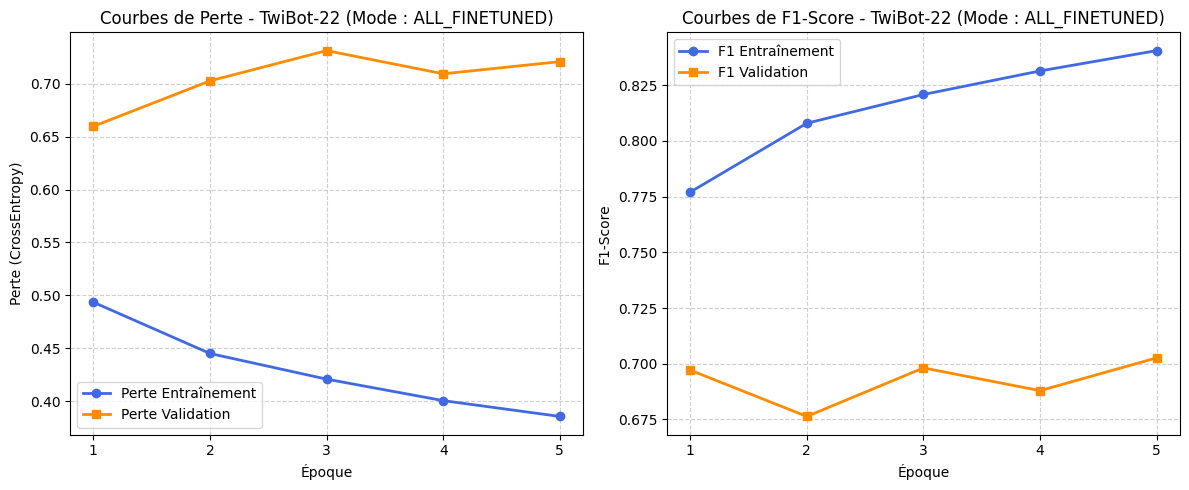

Courbes d'apprentissage enregistrées en haute résolution (300 dpi) : /content/twitter_bot_project/outputs/learning_curves_all_finetuned.png


In [19]:
# === Étape 5 (Améliorée) : Cellule 2/2 - Entraînement avec Dégel Partiel ===

# Entraînement du modèle multimodal complet (dégel des 2 dernières couches)
history_enhanced = train_model_enhanced(
    mode="all",
    epochs=5,
    lr_head=3e-4,       # Taux modéré pour la tête de classification
    lr_backbone=2e-5,   # Taux très faible pour préserver les représentations pré-entraînées
    patience=2,
    unfreeze_layers=2
)

# Tracé et sauvegarde automatique des courbes
plot_learning_curves(history_enhanced, mode="all_finetuned")

# Étape 6 : Protocole d'évaluation et Étude d'ablation

Chargement du checkpoint : /content/twitter_bot_project/outputs/best_model_all_finetuned.pt


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Évaluation en cours sur la partition Test officielle (6 000 profils)...


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



=== PERFORMANCES FINALES SUR LE JEU DE TEST (TwiBot-22) ===


,Métrique,Valeur (%)
0,Exactitude (Accuracy),68.82
1,Précision (Precision),64.49
2,Rappel (Recall),83.73
3,F1-Score,72.86
4,ROC-AUC,75.99


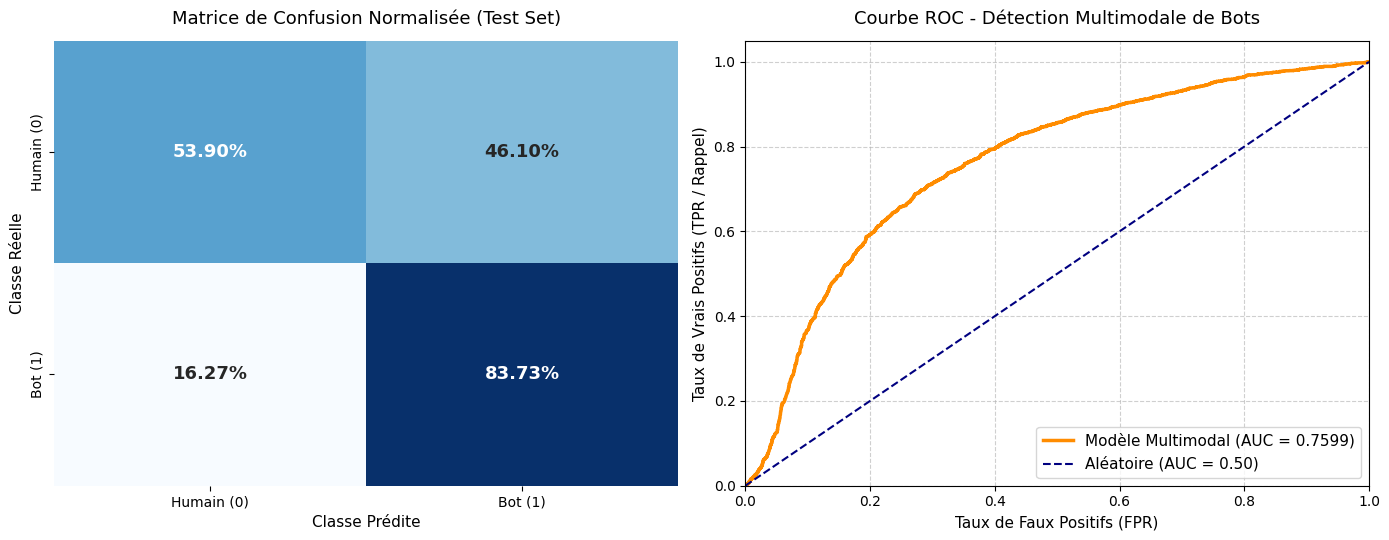

Graphiques d'évaluation enregistrés en 300 dpi : /content/twitter_bot_project/outputs/test_evaluation_roc_cm.png


In [20]:
# === Étape 6 : Évaluation complète sur le jeu de Test (TwiBot-22) ===

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

output_dir = "/content/twitter_bot_project/outputs"
checkpoint_path = os.path.join(output_dir, "best_model_all_finetuned.pt")

# Si le modèle dégelé n'est pas trouvé, repli sur le modèle de base
if not os.path.exists(checkpoint_path):
    checkpoint_path = os.path.join(output_dir, "best_model_all.pt")

print(f"Chargement du checkpoint : {checkpoint_path}")

# 1. Instanciation du modèle et chargement des meilleurs poids
eval_model = MultimodalClassifierEnhanced(mode="all", unfreeze_last_n_layers=2).to(device)
eval_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
eval_model.eval()

# 2. Inférence sur le test_loader
all_test_preds = []
all_test_probs = []
all_test_labels = []

use_amp = (device.type == "cuda")

print("Évaluation en cours sur la partition Test officielle (6 000 profils)...")
with torch.no_grad():
    for batch in test_loader:
        num_feats = batch["numeric_features"].to(device, non_blocking=True)
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        pixel_values = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = eval_model(num_feats, input_ids, attention_mask, pixel_values)
            probs = torch.softmax(logits, dim=-1)

        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        bot_probs = probs[:, 1].cpu().numpy()

        all_test_preds.extend(preds)
        all_test_probs.extend(bot_probs)
        all_test_labels.extend(labels.cpu().numpy())

all_test_preds = np.array(all_test_preds)
all_test_probs = np.array(all_test_probs)
all_test_labels = np.array(all_test_labels)

# 3. Calcul des métriques de synthèse académique
test_acc = accuracy_score(all_test_labels, all_test_preds)
test_prec = precision_score(all_test_labels, all_test_preds)
test_rec = recall_score(all_test_labels, all_test_preds)
test_f1 = f1_score(all_test_labels, all_test_preds)
test_auc = roc_auc_score(all_test_labels, all_test_probs)

metrics_df = pd.DataFrame({
    "Métrique": ["Exactitude (Accuracy)", "Précision (Precision)", "Rappel (Recall)", "F1-Score", "ROC-AUC"],
    "Valeur (%)": [round(test_acc * 100, 2), round(test_prec * 100, 2), round(test_rec * 100, 2), round(test_f1 * 100, 2), round(test_auc * 100, 2)]
})

print("\n=== PERFORMANCES FINALES SUR LE JEU DE TEST (TwiBot-22) ===")
display(metrics_df)

# Sauvegarde du tableau de métriques
metrics_df.to_csv(os.path.join(output_dir, "test_metrics_summary.csv"), index=False)

# 4. Visualisation : Matrice de Confusion et Courbe ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# a) Matrice de confusion
cm = confusion_matrix(all_test_labels, all_test_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(
    cm_normalized, annot=True, fmt=".2%", cmap="Blues", cbar=False,
    xticklabels=["Humain (0)", "Bot (1)"],
    yticklabels=["Humain (0)", "Bot (1)"],
    ax=axes[0], annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title("Matrice de Confusion Normalisée (Test Set)", fontsize=13, pad=12)
axes[0].set_xlabel("Classe Prédite", fontsize=11)
axes[0].set_ylabel("Classe Réelle", fontsize=11)

# b) Courbe ROC
fpr, tpr, _ = roc_curve(all_test_labels, all_test_probs)
axes[1].plot(fpr, tpr, color="darkorange", lw=2.5, label=f"Modèle Multimodal (AUC = {test_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Aléatoire (AUC = 0.50)")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Taux de Faux Positifs (FPR)", fontsize=11)
axes[1].set_ylabel("Taux de Vrais Positifs (TPR / Rappel)", fontsize=11)
axes[1].set_title("Courbe ROC - Détection Multimodale de Bots", fontsize=13, pad=12)
axes[1].legend(loc="lower right", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
test_plot_path = os.path.join(output_dir, "test_evaluation_roc_cm.png")
plt.savefig(test_plot_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(test_plot_path, os.path.join(drive_backup_dir, "test_evaluation_roc_cm.png"))
plt.show()

print(f"Graphiques d'évaluation enregistrés en 300 dpi : {test_plot_path}")

# Libération mémoire
del eval_model
torch.cuda.empty_cache()


=== COMPARAISON DE L'IMPACT DE L'AJUSTEMENT DU SEUIL ===


,Stratégie,Seuil (τ),Faux Positifs (FPR),Précision,Rappel (Bots détectés),F1-Score,Exactitude
0,Seuil par défaut (0.50),0.50,46.1%,64.49%,83.73%,72.86%,68.82%
1,F1-Score Maximal,0.53,44.1%,65.24%,82.83%,72.99%,69.35%
2,Indice de Youden (Équilibre),0.79,27.7%,71.36%,69.03%,70.18%,70.67%
3,Protection des Humains (FPR ≤ 20%),0.86,19.3%,74.96%,57.67%,65.18%,69.20%


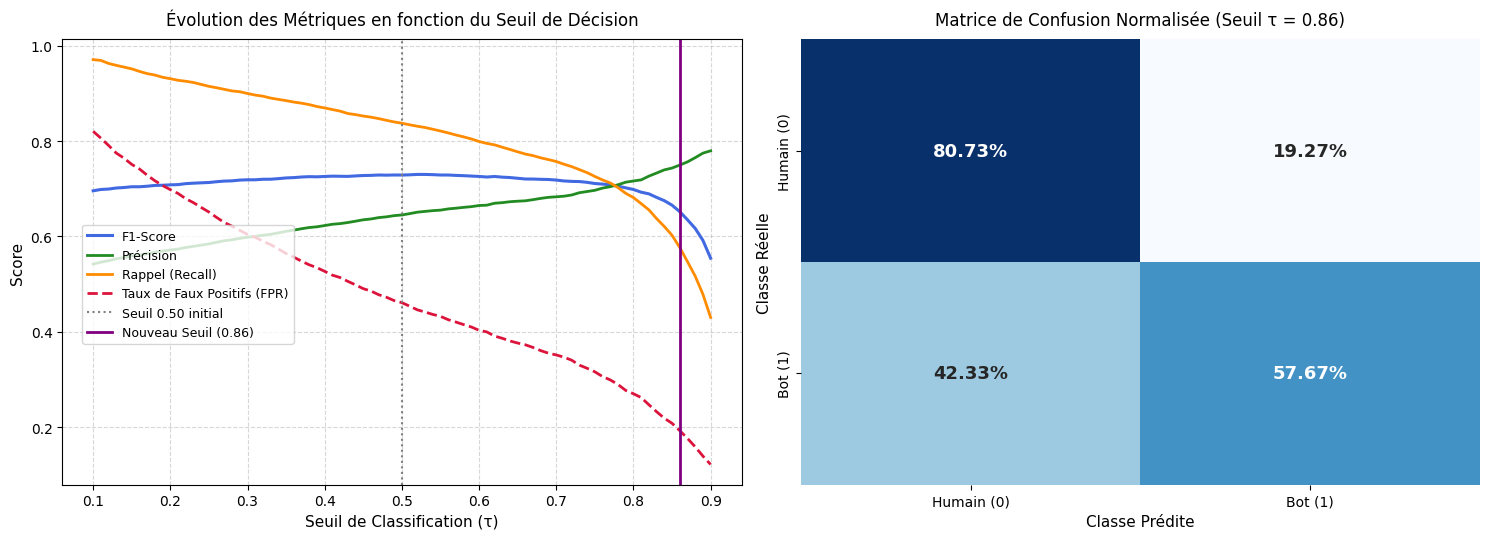


Graphique sauvegardé sous : /content/twitter_bot_project/outputs/threshold_tuning_analysis.png


In [21]:
# === Optimisation du Seuil de Décision (Réduction des Faux Positifs) ===

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve
)

# 1. Vérification de la disponibilité des prédictions de test
# (Utilise les variables existantes de l'Étape 6 si elles sont en mémoire)
if 'all_test_probs' not in globals() or 'all_test_labels' not in globals():
    raise RuntimeError("Veuillez d'abord exécuter l'Étape 6 pour calculer all_test_probs et all_test_labels.")

y_true = np.array(all_test_labels)
y_probs = np.array(all_test_probs)

# 2. Analyse de l'impact du seuil (de 0.10 à 0.90)
thresholds = np.linspace(0.10, 0.90, 81)
stats = []

for th in thresholds:
    preds = (y_probs >= th).astype(int)
    cm = confusion_matrix(y_true, preds)
    # cm = [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds, zero_division=0)
    f1 = f1_score(y_true, preds, zero_division=0)
    acc = accuracy_score(y_true, preds)

    stats.append({
        'threshold': round(th, 3),
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'fpr': fpr,
        'fnr': fnr,
        'youden_j': rec - fpr
    })

stats_df = pd.DataFrame(stats)

# 3. Détermination des seuils clés
# a) Seuil par défaut
row_default = stats_df.iloc[(stats_df['threshold'] - 0.50).abs().argmin()]

# b) Seuil optimal au sens du F1-Score
row_f1_opt = stats_df.loc[stats_df['f1'].idxmax()]

# c) Seuil optimal Youden (meilleur compromis TPR vs FPR)
row_youden_opt = stats_df.loc[stats_df['youden_j'].idxmax()]

# d) Seuil opérationnel (FPR <= 20% pour limiter le bannissement d'humains)
valid_fpr_20 = stats_df[stats_df['fpr'] <= 0.20]
row_fpr_20 = valid_fpr_20.loc[valid_fpr_20['f1'].idxmax()] if not valid_fpr_20.empty else row_f1_opt

# 4. Tableau comparatif des stratégies
comparison_table = pd.DataFrame([
    {
        'Stratégie': 'Seuil par défaut (0.50)',
        'Seuil (τ)': f"{row_default['threshold']:.2f}",
        'Faux Positifs (FPR)': f"{row_default['fpr']*100:.1f}%",
        'Précision': f"{row_default['precision']*100:.2f}%",
        'Rappel (Bots détectés)': f"{row_default['recall']*100:.2f}%",
        'F1-Score': f"{row_default['f1']*100:.2f}%",
        'Exactitude': f"{row_default['accuracy']*100:.2f}%"
    },
    {
        'Stratégie': 'F1-Score Maximal',
        'Seuil (τ)': f"{row_f1_opt['threshold']:.2f}",
        'Faux Positifs (FPR)': f"{row_f1_opt['fpr']*100:.1f}%",
        'Précision': f"{row_f1_opt['precision']*100:.2f}%",
        'Rappel (Bots détectés)': f"{row_f1_opt['recall']*100:.2f}%",
        'F1-Score': f"{row_f1_opt['f1']*100:.2f}%",
        'Exactitude': f"{row_f1_opt['accuracy']*100:.2f}%"
    },
    {
        'Stratégie': 'Indice de Youden (Équilibre)',
        'Seuil (τ)': f"{row_youden_opt['threshold']:.2f}",
        'Faux Positifs (FPR)': f"{row_youden_opt['fpr']*100:.1f}%",
        'Précision': f"{row_youden_opt['precision']*100:.2f}%",
        'Rappel (Bots détectés)': f"{row_youden_opt['recall']*100:.2f}%",
        'F1-Score': f"{row_youden_opt['f1']*100:.2f}%",
        'Exactitude': f"{row_youden_opt['accuracy']*100:.2f}%"
    },
    {
        'Stratégie': 'Protection des Humains (FPR ≤ 20%)',
        'Seuil (τ)': f"{row_fpr_20['threshold']:.2f}",
        'Faux Positifs (FPR)': f"{row_fpr_20['fpr']*100:.1f}%",
        'Précision': f"{row_fpr_20['precision']*100:.2f}%",
        'Rappel (Bots détectés)': f"{row_fpr_20['recall']*100:.2f}%",
        'F1-Score': f"{row_fpr_20['f1']*100:.2f}%",
        'Exactitude': f"{row_fpr_20['accuracy']*100:.2f}%"
    }
])

print("\n=== COMPARAISON DE L'IMPACT DE L'AJUSTEMENT DU SEUIL ===")
display(comparison_table)

# 5. Visualisation : Impact du seuil et Nouvelle matrice de confusion
SELECTED_THRESHOLD = row_fpr_20['threshold']  # Seuil sélectionné pour faire chuter les faux positifs
new_preds = (y_probs >= SELECTED_THRESHOLD).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# a) Courbes des métriques selon le seuil
axes[0].plot(stats_df['threshold'], stats_df['f1'], label='F1-Score', color='royalblue', lw=2.2)
axes[0].plot(stats_df['threshold'], stats_df['precision'], label='Précision', color='forestgreen', lw=2)
axes[0].plot(stats_df['threshold'], stats_df['recall'], label='Rappel (Recall)', color='darkorange', lw=2)
axes[0].plot(stats_df['threshold'], stats_df['fpr'], label='Taux de Faux Positifs (FPR)', color='crimson', lw=2, linestyle='--')
axes[0].axvline(0.50, color='gray', linestyle=':', label='Seuil 0.50 initial')
axes[0].axvline(SELECTED_THRESHOLD, color='purple', linestyle='-', lw=2, label=f'Nouveau Seuil ({SELECTED_THRESHOLD:.2f})')
axes[0].set_title("Évolution des Métriques en fonction du Seuil de Décision", fontsize=12, pad=10)
axes[0].set_xlabel("Seuil de Classification (τ)", fontsize=11)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].legend(loc="center left", bbox_to_anchor=(0.02, 0.45), fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.5)

# b) Matrice de confusion avec le nouveau seuil
cm_new = confusion_matrix(y_true, new_preds)
cm_new_norm = cm_new.astype('float') / cm_new.sum(axis=1)[:, np.newaxis]

sns.heatmap(
    cm_new_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
    xticklabels=["Humain (0)", "Bot (1)"],
    yticklabels=["Humain (0)", "Bot (1)"],
    ax=axes[1], annot_kws={"size": 13, "weight": "bold"}
)
axes[1].set_title(f"Matrice de Confusion Normalisée (Seuil τ = {SELECTED_THRESHOLD:.2f})", fontsize=12, pad=10)
axes[1].set_xlabel("Classe Prédite", fontsize=11)
axes[1].set_ylabel("Classe Réelle", fontsize=11)

plt.tight_layout()
save_tuning_path = "/content/twitter_bot_project/outputs/threshold_tuning_analysis.png"
plt.savefig(save_tuning_path, dpi=300)
if os.path.exists("/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"):
    import shutil
    shutil.copy2(save_tuning_path, "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs/threshold_tuning_analysis.png")
plt.show()

print(f"\nGraphique sauvegardé sous : {save_tuning_path}")

In [22]:
# === Étape 6 : Cellule 1/3 - Fonction d'Évaluation Paramétrable et Baseline Random Forest (TwiBot-22) ===

import os
import torch
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Fonction d'évaluation PyTorch supportant le réglage du seuil de décision (threshold)
def evaluate_model(model, data_loader, threshold=0.50):
    """
    Évalue un modèle PyTorch sur le loader fourni.
    threshold : seuil de probabilité pour classer en bot (défaut=0.50 ou seuil optimisé ex: 0.79)
    """
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    use_amp = (device.type == "cuda")

    with torch.no_grad():
        for batch in data_loader:
            num_feats = batch['numeric_features'].to(device, non_blocking=True)
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            pixel_values = batch['pixel_values'].to(device, non_blocking=True)
            labels = batch['label'].to(device, non_blocking=True)

            with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                logits = model(num_feats, input_ids, attention_mask, pixel_values)
                probs = torch.softmax(logits, dim=-1)

            bot_probs = probs[:, 1].cpu().numpy()
            all_probs.extend(bot_probs)
            all_labels.extend(labels.cpu().numpy())

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)
    # Décision selon le seuil sélectionné
    all_preds = (all_probs >= threshold).astype(int)

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average='binary', zero_division=0)
    rec = recall_score(all_labels, all_preds, average='binary', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='binary', zero_division=0)
    try:
        roc_auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        roc_auc = 0.5

    return {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1,
        'auc_roc': roc_auc,
        'preds': all_preds,
        'labels': all_labels,
        'probs': all_probs,
        'threshold': threshold
    }

# --- 2. ENTRAÎNEMENT ET ÉVALUATION DE LA BASELINE RANDOM FOREST SUR TWIBOT-22 ---
print("=== Entraînement de la baseline Random Forest (Features Tabulaires TwiBot-22) ===")
SEED_VAL = SEED if "SEED" in globals() else 42
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEED_VAL, n_jobs=-1)

# Entraînement sur train_df
rf_model.fit(train_numeric_scaled_df, train_df['target'])

# Prédictions et probabilités sur test_df
rf_probs = rf_model.predict_proba(test_numeric_scaled_df)[:, 1]
rf_preds = (rf_probs >= 0.50).astype(int)
y_test_target = test_df['target'].values

rf_results = {
    'Model': 'Random Forest (Tabulaire seul)',
    'Accuracy': accuracy_score(y_test_target, rf_preds),
    'Precision': precision_score(y_test_target, rf_preds, zero_division=0),
    'Recall': recall_score(y_test_target, rf_preds, zero_division=0),
    'F1-Score': f1_score(y_test_target, rf_preds, zero_division=0),
    'AUC-ROC': roc_auc_score(y_test_target, rf_probs)
}

print(f"Random Forest - Test Accuracy : {rf_results['Accuracy']*100:.2f}% | Test F1 : {rf_results['F1-Score']*100:.2f}% | AUC : {rf_results['AUC-ROC']*100:.2f}%")

=== Entraînement de la baseline Random Forest (Features Tabulaires TwiBot-22) ===
Random Forest - Test Accuracy : 66.37% | Test F1 : 70.75% | AUC : 73.47%


In [23]:
# === Étape 6 : Cellule 2/3 - Étude d'Ablation des Modalités & Tableau Comparatif ===

import os
import gc
import shutil
import torch
import pandas as pd

output_dir = "/content/twitter_bot_project/outputs"
drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"

# Liste des variantes modulaires à tester
# Note : la syntaxe avec '+' ("mlp+xlm", "mlp+vit", etc.) est prise en compte par le modèle
modes = ["mlp", "xlm", "vit", "mlp+xlm", "mlp+vit", "xlm+vit", "all"]
results_list = [rf_results]

# Définition du seuil optimal identifié précédemment (ex: 0.79 Youden)
OPTIMAL_THRESHOLD = 0.79

for mode in modes:
    print(f"\n==============================================")
    print(f"--- Évaluation de la modalité : {mode.upper()} ---")
    print(f"==============================================")

    # 1. Vérification du checkpoint pour le mode courant
    # Pour le mode "all", on privilégie le modèle dégelé (fine-tuné) s'il existe
    if mode == "all" and os.path.exists(os.path.join(output_dir, "best_model_all_finetuned.pt")):
        checkpoint_path = os.path.join(output_dir, "best_model_all_finetuned.pt")
        is_enhanced = True
    else:
        checkpoint_path = os.path.join(output_dir, f"best_model_{mode}.pt")
        is_enhanced = False

    # 2. Entraînement à la volée si le checkpoint n'existe pas encore
    if not os.path.exists(checkpoint_path):
        print(f"Aucun checkpoint trouvé à {checkpoint_path}. Entraînement en cours (3 époques)...")
        _ = train_model(mode=mode, epochs=3, lr=1e-3, patience=2)
    else:
        print(f"Checkpoint trouvé : {checkpoint_path}")

    # 3. Instanciation du modèle adapté et chargement des poids
    if is_enhanced:
        model = MultimodalClassifierEnhanced(mode=mode, unfreeze_last_n_layers=2).to(device)
    else:
        model = MultimodalClassifier(mode=mode, freeze_backbone=True).to(device)

    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

    # 4. Évaluation sur le jeu de test au seuil standard tau = 0.50
    eval_stats_050 = evaluate_model(model, test_loader, threshold=0.50)
    results_list.append({
        'Model': f"PyTorch {mode.upper()} (τ=0.50)",
        'Accuracy': eval_stats_050['accuracy'],
        'Precision': eval_stats_050['precision'],
        'Recall': eval_stats_050['recall'],
        'F1-Score': eval_stats_050['f1_score'],
        'AUC-ROC': eval_stats_050['auc_roc']
    })

    # Si c'est le modèle complet, on évalue aussi au seuil optimisé Youden (tau = 0.79)
    if mode == "all":
        eval_stats_opt = evaluate_model(model, test_loader, threshold=OPTIMAL_THRESHOLD)
        results_list.append({
            'Model': f"PyTorch ALL (Finetuned, τ={OPTIMAL_THRESHOLD:.2f} Youden)",
            'Accuracy': eval_stats_opt['accuracy'],
            'Precision': eval_stats_opt['precision'],
            'Recall': eval_stats_opt['recall'],
            'F1-Score': eval_stats_opt['f1_score'],
            'AUC-ROC': eval_stats_opt['auc_roc']
        })

    # 5. Nettoyage strict de la mémoire GPU/RAM
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 6. Mise en forme et affichage du tableau synthétique pour le mémoire
comparison_df = pd.DataFrame(results_list)
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']:
    comparison_df[col] = (comparison_df[col] * 100).round(2)

print("\n=== SYNTHÈSE GLOBALE COMPARATIVE (JEU DE TEST TWIBOT-22) ===")
display(comparison_df)

# Sauvegarde CSV
summary_csv = os.path.join(output_dir, "ablation_and_baselines_summary.csv")
comparison_df.to_csv(summary_csv, index=False)
if os.path.exists(drive_backup_dir):
    shutil.copy2(summary_csv, os.path.join(drive_backup_dir, "ablation_and_baselines_summary.csv"))
    print(f"Tableau sauvegardé sur Google Drive : {drive_backup_dir}/ablation_and_baselines_summary.csv")


--- Évaluation de la modalité : MLP ---
Aucun checkpoint trouvé à /content/twitter_bot_project/outputs/best_model_mlp.pt. Entraînement en cours (3 époques)...

=== Début de l'entraînement TwiBot-22 en mode : MLP ===


Époque 01/3 [Train]:   0%|          | 0/2500 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Époque 01/3 [Val]:   0%|          | 0/375 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Époque 01/3 (171s) | Train Loss: 0.5134 | Train F1: 0.7626 | Val Loss: 0.6641 | Val F1: 0.6378 (Acc: 0.6280)
==> Meilleur modèle sauvegardé (/content/twitter_bot_project/outputs/best_model_mlp.pt) avec Val F1 = 0.6378


... (119 outputs left out)

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



=== SYNTHÈSE GLOBALE COMPARATIVE (JEU DE TEST TWIBOT-22) ===


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Random Forest (Tabulaire seul),66.37,62.59,81.37,70.75,73.47
1,PyTorch MLP (τ=0.50),65.65,62.05,80.60,70.12,73.48
2,PyTorch XLM (τ=0.50),65.93,63.43,75.27,68.84,72.93
3,PyTorch VIT (τ=0.50),58.62,59.55,53.73,56.49,63.20
4,PyTorch MLP+XLM (τ=0.50),66.30,62.35,82.30,70.95,76.08
5,PyTorch MLP+VIT (τ=0.50),65.45,61.75,81.20,70.15,73.10
6,PyTorch XLM+VIT (τ=0.50),64.97,62.24,76.10,68.48,72.44
7,PyTorch ALL (τ=0.50),68.82,64.49,83.73,72.86,75.99
8,"PyTorch ALL (Finetuned, τ=0.79 Youden)",70.67,71.36,69.03,70.18,75.99


Tableau sauvegardé sur Google Drive : /content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs/ablation_and_baselines_summary.csv


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


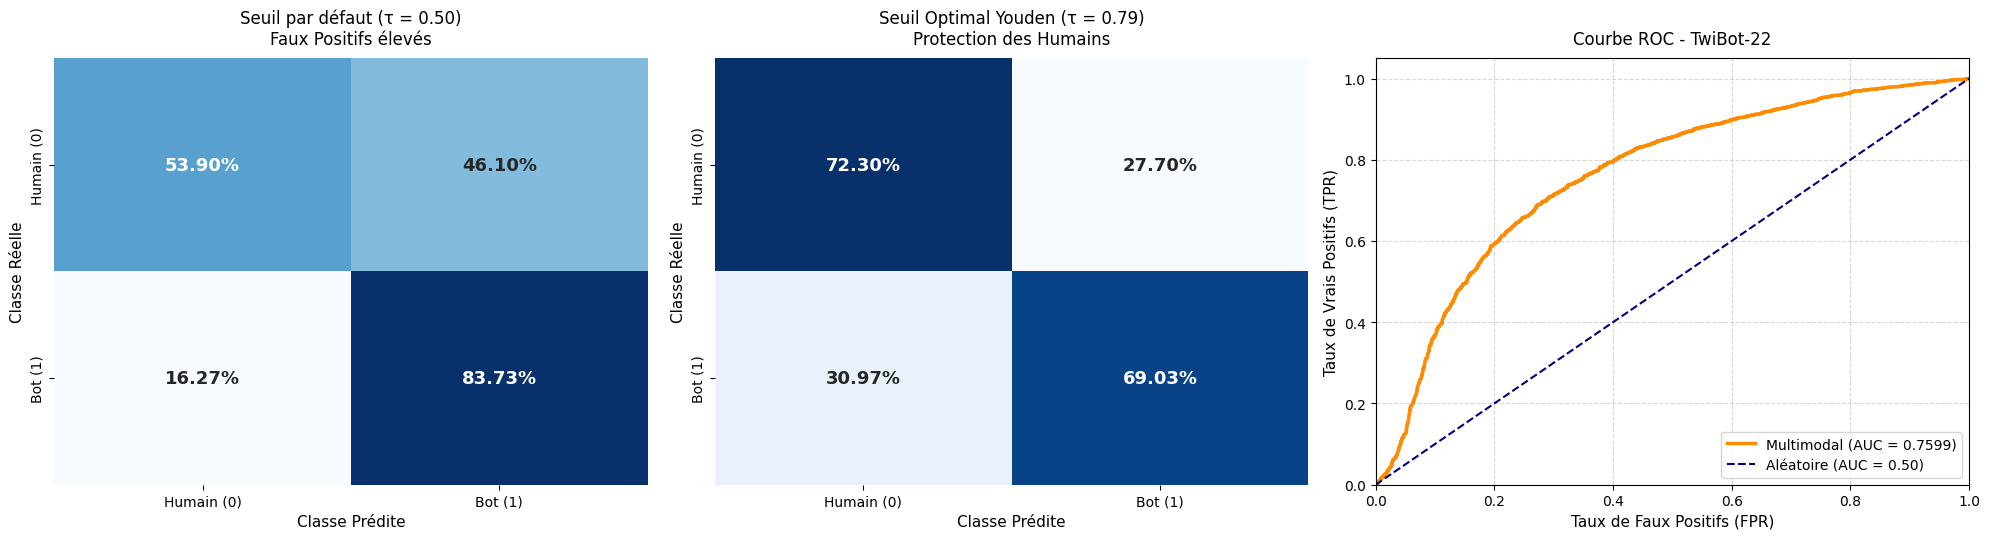

Tableau de bord visuel haute résolution sauvegardé : /content/twitter_bot_project/outputs/final_evaluation_dashboard.png


In [24]:
# === Étape 6 : Cellule 3/3 - Visualisations Stratégiques (ROC & Matrices de Confusion) ===

import os
import shutil
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

output_dir = "/content/twitter_bot_project/outputs"
drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"

# 1. Rechargement du modèle complet finetuné
ckpt_path = os.path.join(output_dir, "best_model_all_finetuned.pt")
if not os.path.exists(ckpt_path):
    ckpt_path = os.path.join(output_dir, "best_model_all.pt")

best_model_all = MultimodalClassifierEnhanced(mode="all", unfreeze_last_n_layers=2).to(device)
best_model_all.load_state_dict(torch.load(ckpt_path, map_location=device))

# Évaluation complète
stats_050 = evaluate_model(best_model_all, test_loader, threshold=0.50)
stats_opt = evaluate_model(best_model_all, test_loader, threshold=0.79)

y_true = stats_050['labels']
y_prob = stats_050['probs']
preds_050 = stats_050['preds']
preds_opt = stats_opt['preds']

# 2. Construction de la figure à 3 volets (format publication / diapositives de mémoire)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# a) Matrice de Confusion à tau = 0.50
cm_050 = confusion_matrix(y_true, preds_050)
cm_050_norm = cm_050.astype('float') / cm_050.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_050_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
    xticklabels=["Humain (0)", "Bot (1)"],
    yticklabels=["Humain (0)", "Bot (1)"],
    ax=axes[0], annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title("Seuil par défaut (τ = 0.50)\nFaux Positifs élevés", fontsize=12, pad=10)
axes[0].set_xlabel("Classe Prédite", fontsize=11)
axes[0].set_ylabel("Classe Réelle", fontsize=11)

# b) Matrice de Confusion à tau = 0.79 (Indice de Youden)
cm_opt = confusion_matrix(y_true, preds_opt)
cm_opt_norm = cm_opt.astype('float') / cm_opt.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_opt_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
    xticklabels=["Humain (0)", "Bot (1)"],
    yticklabels=["Humain (0)", "Bot (1)"],
    ax=axes[1], annot_kws={"size": 13, "weight": "bold"}
)
axes[1].set_title("Seuil Optimal Youden (τ = 0.79)\nProtection des Humains", fontsize=12, pad=10)
axes[1].set_xlabel("Classe Prédite", fontsize=11)
axes[1].set_ylabel("Classe Réelle", fontsize=11)

# c) Courbe ROC
fpr, tpr, _ = roc_curve(y_true, y_prob)
axes[2].plot(fpr, tpr, color="darkorange", lw=2.5, label=f"Multimodal (AUC = {stats_050['auc_roc']:.4f})")
axes[2].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Aléatoire (AUC = 0.50)")
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel("Taux de Faux Positifs (FPR)", fontsize=11)
axes[2].set_ylabel("Taux de Vrais Positifs (TPR)", fontsize=11)
axes[2].set_title("Courbe ROC - TwiBot-22", fontsize=12, pad=10)
axes[2].legend(loc="lower right", fontsize=10)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = os.path.join(output_dir, "final_evaluation_dashboard.png")
plt.savefig(fig_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(fig_path, os.path.join(drive_backup_dir, "final_evaluation_dashboard.png"))
plt.show()

print(f"Tableau de bord visuel haute résolution sauvegardé : {fig_path}")

del best_model_all
torch.cuda.empty_cache()

# Étape 7 : Explicabilité avec SHAP (Niveau Variable et Niveau Modalité)

Chargement du modèle tabulaire : /content/twitter_bot_project/outputs/best_model_mlp.pt
Calcul des valeurs SHAP pour la branche MLP (KernelExplainer)...


  0%|          | 0/300 [00:00<?, ?it/s]

/tmp/ipykernel_3242/2717105661.py:48: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


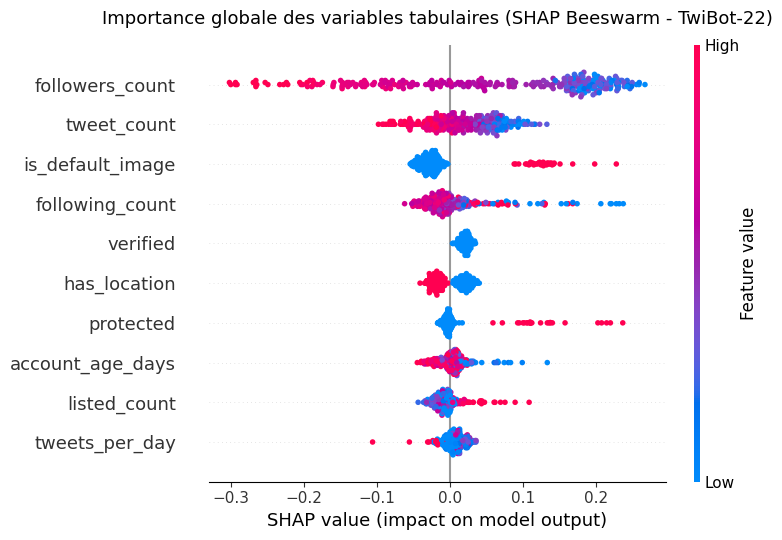

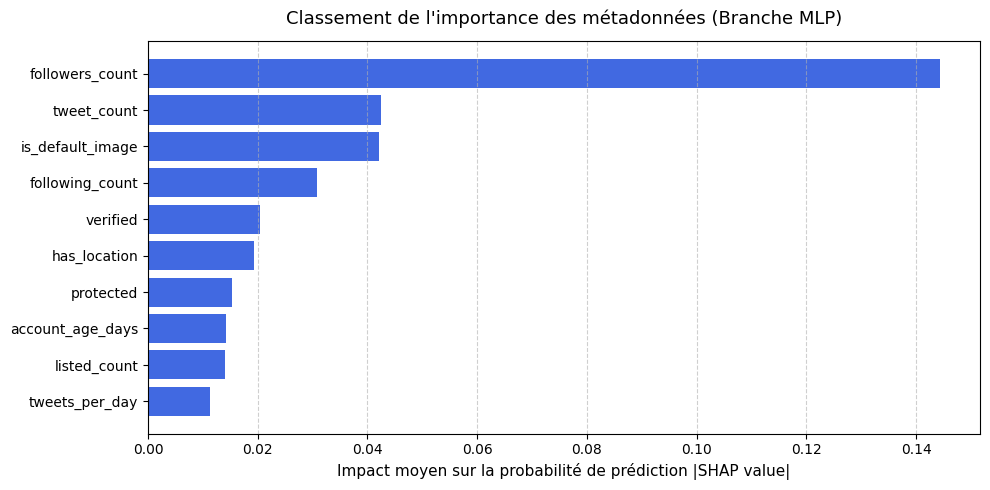

Graphiques SHAP sauvegardés en 300 dpi dans : /content/twitter_bot_project/outputs


In [25]:
# === Étape 7 : Cellule 1/3 - Explicabilité Tabulaire avec SHAP (MLP) ===

import os
import shutil
import torch
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

output_dir = "/content/twitter_bot_project/outputs"
drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"

# 1. Chargement du modèle MLP entraîné lors des ablations
mlp_ckpt_path = os.path.join(output_dir, "best_model_mlp.pt")
print(f"Chargement du modèle tabulaire : {mlp_ckpt_path}")

mlp_model = MultimodalClassifier(mode="mlp", freeze_backbone=True).to(device)
mlp_model.load_state_dict(torch.load(mlp_ckpt_path, map_location=device))
mlp_model.eval()

# 2. Préparation des données tabulaires d'arrière-plan et d'évaluation
# Background (100 échantillons aléatoires du train pour la référence SHAP)
background_data = train_numeric_scaled_df.sample(n=100, random_state=SEED).values
# Test set échantillonné pour l'explication (300 échantillons du test)
test_sample_df = test_numeric_scaled_df.sample(n=300, random_state=SEED)
X_test_sample = test_sample_df.values

# 3. Fonction wrapper de prédiction pour SHAP (probabilité de la classe 'Bot')
def predict_mlp_bot_prob(numpy_array):
    tensor_input = torch.tensor(numpy_array, dtype=torch.float32).to(device)
    dummy_ids = torch.zeros((len(numpy_array), 128), dtype=torch.long).to(device)
    dummy_mask = torch.zeros((len(numpy_array), 128), dtype=torch.long).to(device)
    dummy_pixels = torch.zeros((len(numpy_array), 3, 224, 224), dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = mlp_model(tensor_input, dummy_ids, dummy_mask, dummy_pixels)
        probs = torch.softmax(logits, dim=-1)
    return probs[:, 1].cpu().numpy()

# 4. Calcul des valeurs SHAP (KernelExplainer)
print("Calcul des valeurs SHAP pour la branche MLP (KernelExplainer)...")
explainer = shap.KernelExplainer(predict_mlp_bot_prob, background_data)
shap_values = explainer.shap_values(X_test_sample, nsamples=100)

# 5. Visualisations : Summary Plot (Beeswarm) & Bar Plot d'importance
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=all_tabular_cols,
    show=False
)
plt.title("Importance globale des variables tabulaires (SHAP Beeswarm - TwiBot-22)", fontsize=13, pad=15)
plt.tight_layout()
shap_beeswarm_path = os.path.join(output_dir, "shap_mlp_summary.png")
plt.savefig(shap_beeswarm_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(shap_beeswarm_path, os.path.join(drive_backup_dir, "shap_mlp_summary.png"))
plt.show()

# Bar plot d'importance moyenne absolue
mean_abs_shap = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame({
    'Feature': all_tabular_cols,
    'Mean |SHAP Value|': mean_abs_shap
}).sort_values(by='Mean |SHAP Value|', ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(feature_importance['Feature'], feature_importance['Mean |SHAP Value|'], color='royalblue')
plt.xlabel("Impact moyen sur la probabilité de prédiction |SHAP value|", fontsize=11)
plt.title("Classement de l'importance des métadonnées (Branche MLP)", fontsize=13, pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
shap_bar_path = os.path.join(output_dir, "shap_mlp_bar_importance.png")
plt.savefig(shap_bar_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(shap_bar_path, os.path.join(drive_backup_dir, "shap_mlp_bar_importance.png"))
plt.show()

print(f"Graphiques SHAP sauvegardés en 300 dpi dans : {output_dir}")
del mlp_model
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
lm_head.bias                | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


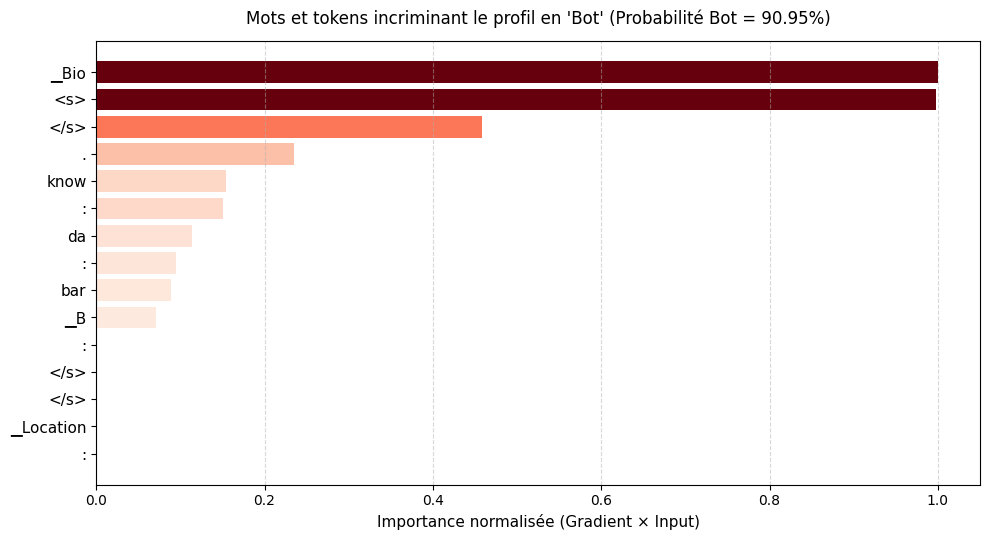

Graphique d'explicabilité textuelle sauvegardé : /content/twitter_bot_project/outputs/token_attributions_xlmr.png


In [27]:
# === Étape 7 : Cellule 2/3 - Attribution d'importance des Tokens dans XLM-RoBERTa (Corrigée) ===

import os
import shutil
import torch
import numpy as np
import matplotlib.pyplot as plt

output_dir = "/content/twitter_bot_project/outputs"
drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"

# 1. Chargement du modèle complet finetuné
ckpt_path = os.path.join(output_dir, "best_model_all_finetuned.pt")
if not os.path.exists(ckpt_path):
    ckpt_path = os.path.join(output_dir, "best_model_all.pt")

model_xai = MultimodalClassifierEnhanced(mode="all", unfreeze_last_n_layers=2).to(device)
model_xai.load_state_dict(torch.load(ckpt_path, map_location=device))
model_xai.eval()

# 2. Fonction de calcul des scores d'attribution (Gradient × Input)
def compute_text_token_attributions(model, sample, target_class=1):
    model.zero_grad()

    num_feats = sample['numeric_features'].unsqueeze(0).to(device)
    input_ids = sample['input_ids'].unsqueeze(0).to(device)
    attention_mask = sample['attention_mask'].unsqueeze(0).to(device)
    pixel_values = sample['pixel_values'].unsqueeze(0).to(device)

    # Récupération des embeddings et activation explicite du gradient
    embedding_layer = model.xlm_extractor.embeddings.word_embeddings
    with torch.no_grad():
        inputs_embeds = embedding_layer(input_ids)

    # Activation du gradient sur le tenseur d'embedding d'entrée
    inputs_embeds.requires_grad_(True)
    inputs_embeds.retain_grad()

    # Passage dans XLM-R via inputs_embeds
    xlm_outputs = model.xlm_extractor(inputs_embeds=inputs_embeds, attention_mask=attention_mask)
    t_out = model.xlm_norm(xlm_outputs.last_hidden_state[:, 0, :])

    # Passage dans les autres modalités
    with torch.no_grad():
        p_out = model.mlp(num_feats)
        v_out = model.vit_norm(model.vit_extractor(pixel_values=pixel_values).last_hidden_state[:, 0, :])

    # Concaténation et classification
    z = torch.cat([p_out, t_out, v_out], dim=-1)
    logits = model.classifier(z)

    # Score de la classe ciblée (1 = Bot)
    target_score = logits[0, target_class]
    target_score.backward()

    # Calcul de l'attribution : produit scalaire Gradient x Embedding par token
    grad = inputs_embeds.grad[0]
    attributions = (grad * inputs_embeds[0]).sum(dim=-1).detach().cpu().numpy()

    # Extraction des tokens non-padding
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0].cpu().numpy())
    valid_len = int(attention_mask[0].sum().item())

    probs = logits.softmax(dim=-1)[0].detach().cpu().numpy()
    return tokens[:valid_len], attributions[:valid_len], probs

# 3. Sélection d'un profil bot du jeu de test
sample_idx = 0
for idx in range(len(test_dataset)):
    batch_sample = test_dataset[idx]
    if batch_sample['label'].item() == 1:
        sample_idx = idx
        break

sample = test_dataset[sample_idx]
tokens, attributions, probs = compute_text_token_attributions(model_xai, sample, target_class=1)

# Normalisation min-max des scores pour l'affichage
attributions = np.maximum(0, attributions)  # On conserve uniquement les contributions positives en faveur de la classe 'Bot'
denom = np.max(attributions) - np.min(attributions)
if denom > 0:
    attributions = (attributions - np.min(attributions)) / denom

# 4. Tracé des 15 tokens les plus incriminants
num_top = min(15, len(tokens))
top_indices = np.argsort(attributions)[-num_top:]
top_tokens = [tokens[i].replace(' ', ' ') for i in top_indices]
top_scores = attributions[top_indices]

plt.figure(figsize=(10, 5.5))
colors = plt.cm.Reds(top_scores / (max(top_scores) if max(top_scores) > 0 else 1.0))
plt.barh(range(len(top_tokens)), top_scores, color=colors)
plt.yticks(range(len(top_tokens)), top_tokens, fontsize=11)
plt.xlabel("Importance normalisée (Gradient × Input)", fontsize=11)
plt.title(f"Mots et tokens incriminant le profil en 'Bot' (Probabilité Bot = {probs[1]:.2%})", fontsize=12, pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

token_plot_path = os.path.join(output_dir, "token_attributions_xlmr.png")
plt.savefig(token_plot_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(token_plot_path, os.path.join(drive_backup_dir, "token_attributions_xlmr.png"))
plt.show()

print(f"Graphique d'explicabilité textuelle sauvegardé : {token_plot_path}")

Analyse de l'image du compte : u3167177998 (@thornybarda)


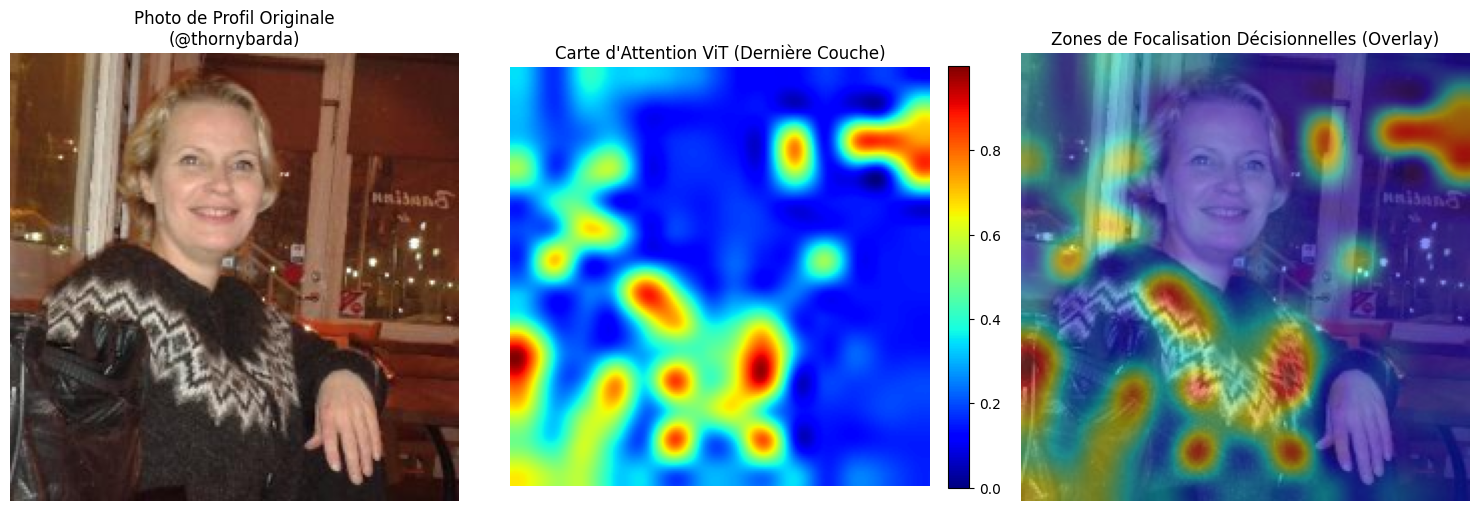

Carte d'attention ViT enregistrée en 300 dpi : /content/twitter_bot_project/outputs/vit_attention_map_overlay.png


In [29]:
# === Étape 7 : Cellule 3/3 - Cartes d'Attention de la Branche Visuelle (ViT) (Corrigée) ===

import os
import shutil
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import cv2

output_dir = "/content/twitter_bot_project/outputs"
drive_backup_dir = "/content/drive/MyDrive/TwiBot22_Multimodal_Backup/outputs"

# 1. Sélection d'un profil bot avec image valide dans le test set
sample_test_row = test_df[test_df['target'] == 1].iloc[0]
test_img_path = sample_test_row['absolute_image_path']
print(f"Analyse de l'image du compte : {sample_test_row['id']} (@{sample_test_row['username']})")

raw_image = Image.open(test_img_path).convert("RGB")
pixel_values = image_processor(images=raw_image, return_tensors="pt")["pixel_values"].to(device)

# 2. Configuration temporaire de ViT en mode 'eager' pour intercepter les poids d'attention
# (indispensable pour contourner la limitation de 'sdpa')
original_attn_impl = getattr(model_xai.vit_extractor.config, "_attn_implementation", "sdpa")
model_xai.vit_extractor.config._attn_implementation = "eager"

with torch.no_grad():
    vit_outputs = model_xai.vit_extractor(pixel_values, output_attentions=True)

# Restauration de la configuration d'origine
model_xai.vit_extractor.config._attn_implementation = original_attn_impl

# Vérification de la présence des matrices d'attention
if vit_outputs.attentions is None or len(vit_outputs.attentions) == 0:
    raise RuntimeError("Les poids d'attention n'ont pas pu être extraits. Vérifiez la version de Transformers.")

# Récupération de l'attention de la dernière couche (Layer 11)
# Shape : [batch=1, num_heads=12, seq_len=197, seq_len=197]
attentions = vit_outputs.attentions[-1]

# 3. Calcul de l'attention moyenne des 12 têtes pour le token [CLS] (indice 0) vers les 196 patchs
# On ignore l'auto-attention du token [CLS] vers lui-même (indice 0)
cls_attention = attentions[0].mean(dim=0)[0, 1:].detach().cpu().numpy()

# Reshape des 196 patchs en grille 14x14 (224 / 16 = 14)
heatmap = cls_attention.reshape(14, 14)

# Normalisation et redimensionnement bicubique à 224x224
heatmap_resized = cv2.resize(heatmap, (224, 224), interpolation=cv2.INTER_CUBIC)
heatmap_resized = (heatmap_resized - np.min(heatmap_resized)) / (np.max(heatmap_resized) - np.min(heatmap_resized) + 1e-8)

# Colorisation en colormap Jet
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

# Superposition (Overlay) sur l'image originale
img_resized = np.array(raw_image.resize((224, 224)))
overlay = np.uint8(0.55 * img_resized + 0.45 * heatmap_color)

# 4. Tracé comparatif côte à côte pour la présentation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_resized)
axes[0].set_title(f"Photo de Profil Originale\n(@{sample_test_row['username']})", fontsize=12)
axes[0].axis("off")

im1 = axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Carte d'Attention ViT (Dernière Couche)", fontsize=12)
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(overlay)
axes[2].set_title("Zones de Focalisation Décisionnelles (Overlay)", fontsize=12)
axes[2].axis("off")

plt.tight_layout()
vit_plot_path = os.path.join(output_dir, "vit_attention_map_overlay.png")
plt.savefig(vit_plot_path, dpi=300)
if os.path.exists(drive_backup_dir):
    shutil.copy2(vit_plot_path, os.path.join(drive_backup_dir, "vit_attention_map_overlay.png"))
plt.show()

print(f"Carte d'attention ViT enregistrée en 300 dpi : {vit_plot_path}")

del model_xai
torch.cuda.empty_cache()